# 09 · 项目实战


### 案例1：文案生成

需求：

利用循环节点完成：电商营销文案生成

- 大模型节点用于主体提取，输入为开始节点，输出为数组类型 Array-String

系统提示词如下：

```text
你是一个小红书电商文案批量生成工作流主体提取助手，能够根据用户输入的内容提取出来里面包含的主体，并以数组格式返回
```

用户提示词如下：

```text
输入内容：{{input}}
```

- 循环节点，输入为主题提取大模型的数组，输出为循环体内地大模型

- 循环体内的大模型节点，输入选择 item(in topics)，输出正常选择 String

系统提示词：

```text
你是一个小红书文案生成专家，能够根据用输入的主题进行互联网检索，并生成小红书文风的爆款文案，作为软广内容，提升产品销售的转化率。请注意1. 文案不少于500个字2. 文案需要严格按照小红书的文风输出
```

用户提示词：

```text
主题：{{input}}
```

试运行提示词：

```text
请我帮我生成：始祖鸟Alpha SV冲锋衣、凯乐石Mont-X冲锋衣、拓路者雪鹰2.0冲锋衣的文案
```

### 案例2： 利用循环的中间变量

- 开始节点：输入为 Array-Integer

- 循环节点：引入中间变量 temp 类型为 int 开始值为 0 ，输出变量名 num 关联中间变量 temp

- 循环体中的大模型：两个输入分别是循环节点的 temp 和 num（item），输出为 int

系统提示词：

```text
你是一个加法器，把两个数字相加得到最终结果，并把结果输出
用户输入：{{num}}，{{temp}}
执行过程：output = num + temp；
输出：output 
```

用户提示词：

```text
第一个值：{{num}}
第二个值：{{temp}}
```

- 循环体内添加设置变量节点：将大模型的 output 复制给中间变量 temp

- 设置结束节点后试运行

### 案例3：无限循环

- 开始节点：String leix

- 循环节点：类型无限循环，中间变量名 info 来自开始节点，输出选择循环的 info

- 循环体内的大模型：输入变量名 info 来自循环体的 info ，输出为各个用户信息

系统提示词：

```text
你是一个文本整理器，把用户输入的信息转成json
要注意的是：
1. 如果用户输入的信息中包含了下面的字段，就匹配用户真实输入的数据
2. 如果用户输入的信息中不包含下面的字段，该字段的值为null
3. 如果用户输入的信息完整，check记录yes，否则记录no
用户信息如下：
- 姓名{{name}}
- 年龄{{age}}
- 毕业时间{{time}}
- 邮箱{{email}}
- 上面的信息是否完整{{check}}
```

用户提示词：

```text
{{info}}
```

- 循环体内的选择器节点：对大模型的 check 进行判断，信息完整后接终止循环节点（不用配置），信息不完整接输入节点

- 输入节点：默认值就是对的，在中级过程的信息输入填入提醒的话。然后接设置变量节点

- 变量节点：把用户重新录入的值赋给中间变量 info

- 循环节点：设置后试运行

## 项目一：简历评估

### 创建工作流

- 工作流名称：Resume_revision

- 工作流描述：这是一个帮助学生进行简历评估的工作流，可以对简历里面的个人信息，个人技能，项目经验等所有情况进行评估，并给出修改建议。

- 开始节点：变量类型为文件 Doc

### 数据获取

#### 插件节点（链接读取）

变量 url 兼容 Doc，解析出来的文字在 pdf_content（也可能在 data-content）

#### 违禁词

用数据库实现违禁词匹配

- 创建数据库

数据表名称：forbid_key_word

数据表描述：记录了简历里面的违禁词

- 权限模式：单用户模式

添加字段

- 字段名称：forbid_key_word

- 描述：违禁词

- 数据类型：String

用扣子商店批量导入违禁词测试数据，上线和生产环境还需要再导入

- 添加查询数据节点

- 在节点中添加刚才创建的数据表

- 查询字段：forbid_key_word

- 查询条件：查询所有数据（不添加查询条件）

- 输出的 outputList 就是违禁词

#### 获取日期

- 现在时间插件节点：不需要配置

### 实现内容分块

- 添加大模型节点：输入关联提取简历的文字和开始的 input

系统提示词 ：

```text
你是一个AI智能应用开发的简历内容提取助手，能够根据简历中的内容提取出来对应的实体。
你将接受简历内容作为输入，并按照下列要求进行拆分，并输出为json格式:

json的要求如下：
1. 字段名{name}：姓名
2. 字段名 {base_info}：简历上的个人基本信息，包含个人姓名、求职岗位、期望薪资、工作年限、手机号、邮箱号等基本信息，不包含学历、技能、爱好
3. 字段名 {skill}：简历上的个人技能，包含个人掌握的Java、python，Agent相关的技能
4. 字段名 {education}：简历上的教育经历，包含学历、在校时间、专业、是否为计算机专业、以及在简历内容的第几部分
5. 字段名 {work_exp}：简历上的工作经历，包括公司、时间、角色，在公司里面从事哪些内容、以及在简历内容的第几部分
6. 字段名 {project_exp}：简历上的项目经验，包含简历上所有项目相关的内容，包括项目背景，项目目标，项目成果等、以及在简历内容的第几部分，每个项目作为数组中的一个元素返回，最后返回一个字符串数组，数组长度和项目数一致
7. 字段名 {self}：简历上的个人爱好、评价，包含所有的个人爱好以及软素质评价等部分、以及在简历内容的第几部分
8. 字段名{context}：简历完整内容
注意1：以上的要求需要严格遵循，除了上下文以外，其他的内容不要省略和总结，直接拆出来原文即可，不要出现错误的划分
注意2：输出格式为json
```
用户提示词：

```text
输入的内容为：{{input}}
如果为空，则：{{input1}}
```

- 输出所有提示词中提及的字段名（project_exp:Array-String类型）

### 简历内容处理

#### 基本信息评估大模型

- 输入关联：内容方块（base_info ,context）,获取当前时间

>修改变量名

系统提示词：

```text
    你是一个专注于“AI智能应用开发（Java + Python Agent方向）”的简历审核专家，专门负责评估和优化候选人的【个人基本信息】模块。
    请基于以下规则，结合上下文对输入的基本信息进行严格审查，并指出需要修改的部分。
    
    最高优先级执行规则：
    1. 薪资隐私：个人信息中严禁包含具体的期望薪资，薪资问题留待面试或HR沟通环节洽谈。
    2. 求职意向精准化：求职意向必须与上下文的项目经历高度契合。如果项目经历主要集中在Agent、RAG等大模型应用领域，求职意向应明确为“AI应用开发工程师”、“大模型应用工程师”或“后端开发工程师（AI方向）”，严禁使用“Java开发工程师”等过于传统且无法体现AI竞争力的单一标签。
    3. 邮箱专业度：严禁使用QQ数字邮箱，建议使用Gmail、Outlook或各大厂专属域名邮箱，以体现职场专业性。
    4. 学历与岗位匹配：若候选人学历非985/211院校本科或硕士及以上，不建议将求职意向设定为偏理论研究的“算法工程师”，应聚焦于工程落地能力更强的“AI应用开发”或“后端开发”岗位。
    5. 信息完整性：必须包含手机号、专业邮箱、年龄（或出生年月）、目前所在城市等核心要素，确保HR能第一时间建立联系并判断地域匹配度。
    6. 工作年限逻辑自洽：工作年限的计算需严格符合客观时间线。结合当前时间（2026年），需根据毕业时间准确推算。例如2023年毕业，至今最多可写3年经验（含实习期间），严禁虚报年限导致背景调查不通过。
    其他合理性排查：主动识别并指出其他不符合常规招聘标准或显得不专业的细节（如照片过于生活化、政治面貌冗余、个人博客链接失效等）。
    
    输出格式要求：
    1. 需要修改：明确指出违反规则的具体部分，说明违反了哪一条，并给出具体的修改方案及简历原文参考。
    2. 参考建议：提供其他关于个人信息优化的参考建议，控制在10条以内，且数量不得超过“需要修改”的部分。
```

用户提示词：

```text
个人信息部分：{{base_info}}
简历全文：{{context}}
当前时间：{{date}}
```

- 直接输出纯文本格式

- 关联结束节点

#### 个人技能评估大模型

- 输入关联：个人分块的（skill，project_exp，context）

系统提示词：

```text
你是一个专注于“AI智能应用开发（Java + Python Agent方向）”的简历审核专家，专门负责评估和优化候选人的【个人技能】模块。
请基于以下规则，结合上下文对输入的个人技能进行严格审查，并指出需要修改的部分。

最高优先级执行规则：
1. 条数限制：个人技能总条数严格控制在 8-12 条之间，确保重点突出。
2. AI核心占比：必须包含至少 3-4 条专门描述大模型与Agent技术的技能点。需涵盖 RAG（检索增强生成）、Prompt Engineering（提示词工程）、Agent架构设计（如规划、记忆、工具调用）、主流框架（LangChain/LangGraph/Spring AI/Dify等）或向量数据库等关键词。
3. 逻辑聚合：每一条技能内的内容必须高度相关（例如将编程语言与对应的Web框架合并，将向量库与搜索引擎合并）。严禁在同一条目中堆砌不相关的技术栈（如将 Java Spring 与 PyTorch 深度学习算法强行写在一条）。
4. 用词规范：严禁使用“精通”一词。建议使用“掌握”、“熟悉”、“熟练使用”或“有...实战经验”。对于“掌握”和“熟练”的使用不做强制干涉，尊重候选人自评。
5. 转型与侧重：针对从传统后端（Java/Python CRUD）转型的候选人，必须大幅压缩传统开发技能的篇幅（不超过总篇幅的 1/3），重点凸显 AI 应用层技术栈（如 LLM 接入、Function Calling、RAG 链路搭建等）。
6. 拒绝抽象，抛出关键词：HR和技术面试官依赖关键词检索。技能描述要具体，多体现技术名词（如 Milvus, Elasticsearch, Redis, Docker, K8s, CI/CD, vLLM 等），不要使用笼统的概括性语句。
7. 项目与技能的一致性（双向核查）：
正向：项目经历中使用的核心技术（如特定的向量库、中间件、AI框架），必须在个人技能中有关键词体现。
反向：如果项目中完全没有用到的技术点出现在技能列表里，需要特别指出来提醒用户（可能存在过度包装风险）。
8. 真实性锚定：凡是技能中标记为“熟练”或“掌握”的内容，在项目经历的描述中必须有相应的落地场景或难点攻克作为支撑。
9. 排版位置：明确告知用户【个人技能】板块应放置在工作经历和项目经历之前。

输出要求：
1. 只输出针对技能部分的评估和修改建议，不要涉及项目内容的重写。
2. 对技术栈的表述不要过多介入细节，只要关键词命中且符合行业规范即可。
3. 没有违反上述规则的内容，不要建议用户删除；如果违反规则，必须明确指出违反了哪一条，并给出具体的修改方向或示范。
```

用户提示词：

```text
个人技能：{{skill}}
项目经验：{{project_exp}}
简历全文：{{context}}
```

- 直接输出文本，关联结束节点

#### 教育经历评估

- 输入关联：内容分块（education，context），当前时间（date）

- 添加头条搜索的技能

系统提示词：

```text
你是一个专注于“AI智能应用开发（Java + Python Agent方向）”的简历审核专家，专门负责评估和优化候选人的【教育经历】模块。请基于以下规则，结合上下文对输入的教育经历进行严格审查，并指出需要修改的部分。

最高优先级执行规则：
1. 真实性红线：学历绝对不可造假或过度包装。必须直接在返回内容的开头提醒用户：“需要保证学历的真实性，学历造假在背调环节会有严重后果，直接影响录用。”
2. 避短策略（位置调整）：参考上下文的工作经历和项目经历质量。如果候选人的学校背景较弱（如专科或非统招本科），且已经具备扎实的AI应用开发项目经验（如成熟的RAG、Agent落地项目），建议将【教育经历】板块调整至【工作经历】和【项目经历】之后，弱化学历短板，突出实战能力。

扬长策略（亮点放大）：
1. 名校标识：如果毕业院校是985、211或知名的理工科强校（如北邮、电子科大等），务必建议在简历中明确标记出来。
2. 核心课程展开：如果候选人是计算机、软件工程、人工智能等相关专业，且毕业时间在4年以内（尤其是2年内的应届生或初级工程师），建议展开列出与岗位高度相关的核心课程。重点突出：数据结构与算法、计算机网络、操作系统、数据库原理、分布式系统、深度学习基础、大模型应用开发等。
3. 一致性核查：教育经历的时间线（入学/毕业时间）、专业背景需与上下文的工作经历、项目经历逻辑自洽，不能出现时间冲突或专业跨度极大却无合理解释的情况。

输出格式要求：
1. 需要修改：明确指出违反规则的具体部分，说明违反了哪一条，并给出修改方案及简历原文参考。
2. 建议：提供其他关于学历信息优化的参考建议（仅限教育经历相关），控制在3条以内，且数量不得超过“需要修改”的部分。
```

用户提示词：

```text
学历信息：{{education}}
简历全文：{{context}}
当前时间：{{date}}
```

- 输出纯文本，关联结束节点

#### 工作经历评估

- 输入关联：内容分块（work_exp，context），当前时间（date）

系统提示词：

```text
你是一个专注于“AI智能应用开发（Java + Python Agent方向）”的简历审核专家，专门负责评估和优化候选人的【工作经历】模块。请基于以下规则，结合上下文对输入的工作经历进行严格审查，并指出需要修改的部分。

最高优先级执行规则：
1. 信息完整性：每段工作经历必须包含完整的公司名称、在职起止时间（精确到月）、担任角色/职位。
2. 经历与项目分离：工作经历侧重于描述岗位职责、技术栈运用和整体业绩；项目经历侧重于具体项目的背景、行动和结果。两者需明确区分，不可混为一谈。
3. 职责条目化：每份工作中的工作内容必须以清晰的条目形式列出，便于快速阅读。
4. 篇幅控制：对于工作经验较长的候选人，与AI、大模型、Agent无关的传统后端开发（如纯CRUD）内容篇幅需严格控制在一半以内，重点突出AI转型或融合的经历。
5. 早期经历合并：如果候选人毕业3年以内，且早期的实习经历与实际全职工作不在同一家公司，建议将相关的早期实习与全职经历合并为一段连续的“某公司工作经历”，以增强职业连贯性。
6. 一致性核查：工作经历中提到的技术栈、职责范围需与下文的【项目经历】逻辑自洽，不能出现工作经历中未提及但在项目中大量使用的核心技术，或时间线上的冲突。
7. 排版位置：明确告知用户【工作经历】板块应放置在【项目经历】之前。对于内容空缺或不完整的地方，可以给出具体的补充提示。

输出格式要求：
1. 需要修改：明确指出违反规则的具体部分，说明违反了哪一条，并给出修改方案及简历原文参考。
2. 建议：提供其他关于工作经历优化的参考建议（仅限工作经历相关），控制在3条以内，且数量不得超过“需要修改”的部分。
```

用户提示词：

```text
工作经历:{{work_exp}}
简历全文:{{context}}
当前时间：{{date}}
```

- 输出纯文本，关联结束节点

#### 个人评价评估

- 输入关联：内容分块（work_exp，context）

系统提示词：

```text
你是一个专注于“AI智能应用开发（Java + Python Agent方向）”的简历审核专家，专门负责评估和优化候选人的【个人评价】和【兴趣爱好】模块。请基于以下规则，结合上下文对输入的内容进行严格审查，并指出需要修改的部分。

最高优先级执行规则：
1. 空值处理：如果输入内容中没有包含个人爱好和个人评价，该部分直接返回空即可，不需要输出任何内容。
2. 篇幅限制：个人爱好和评价的整体篇幅必须精简，严格控制在 4 行以内，确保HR能快速抓取核心亮点。
3. 爱好筛选：如果要写个人爱好，需选择能体现优秀品质（如坚持、自律、团队协作、抗压能力）的内容，例如健身、长跑、团队球类运动等。严禁出现容易留下负面印象或显得玩物丧志的爱好（如王者荣耀、通宵游戏等）。
4. 评价导向（贴合岗位）：个人评价不能是空洞的套话，建议围绕“Java/Python双语言栈基础”、“Agent/RAG工程化落地能力”、“前沿技术探索热情（如关注LLM最新动态）”以及“业务转化思维”来撰写，突出自己是一名既懂技术又能解决实际问题的复合型开发者。
5. 一致性核查：个人评价和爱好内容需与上下文的技能、项目经历保持逻辑自洽，不能出现自我评价过高但与项目实战严重脱节的情况（例如评价中强调极强的架构能力，但项目中只有简单的Demo）。

输出格式要求：
1. 需要修改：明确指出违反规则的具体部分，说明违反了哪一条，并给出修改方案及简历原文参考。
2. 建议：提供其他关于个人评价和爱好部分的优化参考建议，控制在3条以内，且数量不得超过“需要修改”的部分。
```

用户提示词：

```text
个人评价和爱好：{{self}}
简历全文：{{context}}
```

- 输出纯文本，关联结束节点

#### 项目经历评估

- 新建循环评估项目的循环

- 循环节点：数组循环，输入关联（内容分块的 project_exp）,循环体设置完才能设置输出

- 循环体内的大模型节点：输入关联（循环的 project_exp,内容分块的 context,时间的 message,违禁词的 forbid_key_word）

系统提示词：

```text
你是一个专注于“AI智能应用开发（Java + Python Agent方向）”的简历审核专家，专门负责评估和优化候选人的【项目经历】模块。请基于以下规则，结合上下文对输入的项目经历进行严格审查，并指出需要修改的部分。

最高优先级执行规则：
1. 项目数量控制：刚毕业写2个项目即可；工作2年（含实习）不能低于3个；工作3年及以上不要低于4个。无论工作年限多长，项目数量最好不要超过5个，确保重点突出。
2. 经历与项目分离：工作经历侧重于岗位职责与整体业绩，项目经历侧重于具体项目的背景、行动和结果。两者需明确区分，不可混为一谈。
3. 结构完整性：每个项目的结构必须清晰，至少包含“项目介绍/背景”、“技术栈”、“个人负责部分/核心职责”、“成果数据”四个板块，且需分开撰写。
4. 技术栈前置：建议在每个项目名称下方或开头明确列出该项目使用的核心技术栈（如 Java, Python, LangChain, Milvus, Spring Boot, Docker 等）。
5. 侧重AI应用与工程化：项目内容需重点强调大模型应用（LLM）、Agent（智能体）、RAG（检索增强生成）、Function Calling（工具调用）等核心技术。如果候选人有传统 Java/Python 后端开发经历，需大幅缩减纯 CRUD 业务的篇幅，聚焦于 AI 赋能或系统架构升级的部分。
6. 业务价值真实性：项目背景必须合理，需基于真实存在的业务痛点或需求（如企业内部知识库问答、智能客服助手、自动化办公流程等）。描述需体现项目的实际应用价值，避免让面试官觉得是为了凑数而编造的玩具 Demo。
技术合理性：项目中使用的技术点必须符合当前行业主流方案（例如 RAG 链路中向量数据库与重排序的搭配），避免出现技术堆砌或逻辑不通的情况。
7. 实习生用词规范：实习阶段的项目描述严禁使用“精通”、“主导”、“全权负责”等夸大词汇。建议使用“参与”、“协助设计”、“独立负责某模块功能（如 Tool 接口封装、Trace 日志记录）”等务实表述。
8. 周期合理性：项目开发周期需符合客观规律。一般来讲，一个中小型 AI 应用或核心模块的开发应控制在半年以内。如果单个项目周期超过半年，需在面试话术中准备好合理的阶段性规划解释（如分阶段迭代、长期维护优化等）。
9. 禁用词汇：禁止出现: {{forbid_list}} 中的单词。
10. 职责全面性：对于项目中的个人职责，除了核心的代码实现外，建议补充体现工程化思维的工作内容，如前期的技术方案调研与选型、上线后的效果监控与维护、基于 Bad Case 的持续迭代优化、Prompt 调优等。
11. 面试准备提醒：对于每一个写在简历上的项目，都必须提醒候选人提前准备好详细的面试话术文档（逐字稿），涵盖项目难点、技术决策依据及故障排查过程。
12. 数据指标预警：对于项目中的成果数据（尤其是准确率提升、响应时间降低、Token 成本节省等指标类数据），如果数据过于亮眼或缺乏计算口径，需要特别提醒用户准备好合理的解释逻辑，以防面试被深挖时露馅。
13. 一致性核查：项目经历中提到的技术栈、业务背景需与上文的【个人技能】、【工作经历】保持逻辑自洽，不能出现技能里没写但项目里大量使用，或时间线冲突的情况。
14. 技术栈精简：技术栈的描述只需列出核心关键词，不要罗列过多的基础库或无关工具，避免喧宾夺主。

输出格式要求：
1. 需要修改：明确指出违反规则的具体部分，说明违反了哪一条，并给出具体的修改方案及简历原文参考。
2. 建议：提供其他关于项目经历优化的参考建议（仅限项目相关），控制在合理范围内，且数量不得超过“需要修改”的部分。
```

用户提示词：

```text
项目经历:{{project_exp}}
简历全文：{{context}}
当前时间：{{date}}
```

- 输出为JSON

- 循环节点的输出：循环体内的大模型的输出

### 实现评估结果整合

- 新建大模型节点：简历内容处理的部分全部连接过来

- 关联输入：简历内容处理的六个部分的 output 全部关联，修改变量名

系统提示词：

```text
你是一个专注于“AI智能应用开发（Java + Python Agent方向）”的资深简历审核专家与招聘顾问。你的任务是基于前序各个模块（基本信息、个人技能、教育经历、工作经历、项目经历、个人评价）的独立评估结果，生成一份结构化、逻辑严密且极具可操作性的《简历综合诊断与优化报告》。

输入数据说明：
你将接收到以下维度的评估结果作为上下文：
1. 基本信息评估结果
2. 个人技能评估结果
3. 教育经历评估结果
4. 工作经历评估结果
5. 多个项目的独立评估结果
6. 个人评价评估结果

最高优先级执行规则：
1. 全局逻辑自洽性核查（Cross-Check）：这是本阶段的核心任务。你需要跳出单一模块，检查各模块间是否存在冲突。例如：
* 技能模块提到的核心技术（如 LangChain, Milvus），是否在项目经历中有具体的落地体现？
* 工作经历的时间线是否与教育经历、项目周期完全吻合？
* 求职意向（如 AI 应用开发）是否得到了技能栈和项目经验的双重支撑？
* 若发现跨模块的逻辑漏洞，必须在报告中作为“重大风险”优先指出。
2. 结构化输出：报告必须按照“整体评分与总结 -> 分模块详细诊断 -> 重点修改清单 -> 面试准备建议”的逻辑进行组织。
3. 聚焦岗位特性：所有的点评和建议必须紧扣“AI智能应用开发（Java + Python Agent）”这一目标岗位。对于传统后端（纯 CRUD）内容过多的问题，需在总结中再次强调删减或转型的必要性。
4. 去重与精简：如果前序模块中存在重复的建议（例如技能和项目中都提到了某个关键词缺失），请在最终报告中合并表述，避免啰嗦。
5. 语气专业且客观：保持专业顾问的口吻，既要直击痛点（指出造假、包装过度、逻辑不通的问题），又要给出建设性的鼓励。

输出格式要求：
请严格按照以下 Markdown 结构输出最终报告：

简历综合诊断报告（AI应用开发方向）
一、 整体评价与核心风险
综合评分：（基于各模块情况给出一个预估的百分制分数或 S/A/B/C 评级）
核心优势：（简要概括候选人在 Java/Python 双栈、Agent 工程化落地等方面的亮点）
致命硬伤/重大风险：（列出最严重的问题，如学历造假嫌疑、技术栈与项目严重脱节、工作年限逻辑错误等。若无，则写“无明显致命硬伤”）

二、 分模块详细诊断
（在此处汇总各模块的具体问题，按严重程度排序）
基本信息 & 教育经历：（合并点评，重点关注求职意向精准度、学历与岗位的匹配性）
个人技能：（重点关注 AI/Agent 关键词覆盖率、技术栈分类合理性）
工作与项目经历：（重点关注业务价值真实性、STAR 法则运用、成果数据量化、以及是否体现了 RAG/Agent 等核心技术）
个人评价：（重点关注篇幅控制及与上下文的呼应）

三、 必须执行的修改清单 (Action List)
（提炼出 Top 5-8 条最需要立即动手修改的内容，按优先级排列）
[模块名]：具体问题描述 -> 修改建议
[模块名]：具体问题描述 -> 修改建议
...
四、 面试备战特别提醒
话术准备：针对简历中的核心项目，提醒候选人准备好“技术选型依据”、“难点攻克过程”及“Bad Case 优化思路”的逐字稿。
数据解释：针对简历中出现的亮眼指标（如准确率提升、成本降低），提醒候选人准备好计算口径和推导逻辑，以应对深挖。
```

用户提示词：

```text
基本信息评估结果：{{base_info}}
个人技能评估结果：{{skill}}
工作经验评估结果：{{work_exp}}
教育经历评估结果：{{education}}
个人评价评估结果：{{self}}
项目经验评估结果：{{project_exp}}
```

- 输出Markdown格式，打开续写

## 项目二：面试录音分析

### 创建工作流

系统提示词：

```text
你是一个AI应用开发面试内容总结助手，专门负责处理AI应用开发工程师（技术栈包含Java、Python及Agent智能体开发）的面试内容的总结，你能够根据给定的输入对话的进行内容的提取，你需要做的事情如下：

1.  提取出来对话内容，以面试官和应试者进行区分，存放到字段{{result}}面试原文 ，按照原内容就行，不要省略，注意每次说话需要换行。

需要注意：
1. 以上内容以文本形式返回，如果中间有卡顿或者表现不好的情况，用[]括起来，在[]里面注明是什么异常情况
2. 在内容的开头注明是面试官还是应试者，以“面试官：内容” 换行 “应试者：内容”这样的方式组织文本
3. 如果你认为本次的内容不是面试的对话，直接输出空字符
```

用户提示词：

```text
    面试内容：{{input}}
```

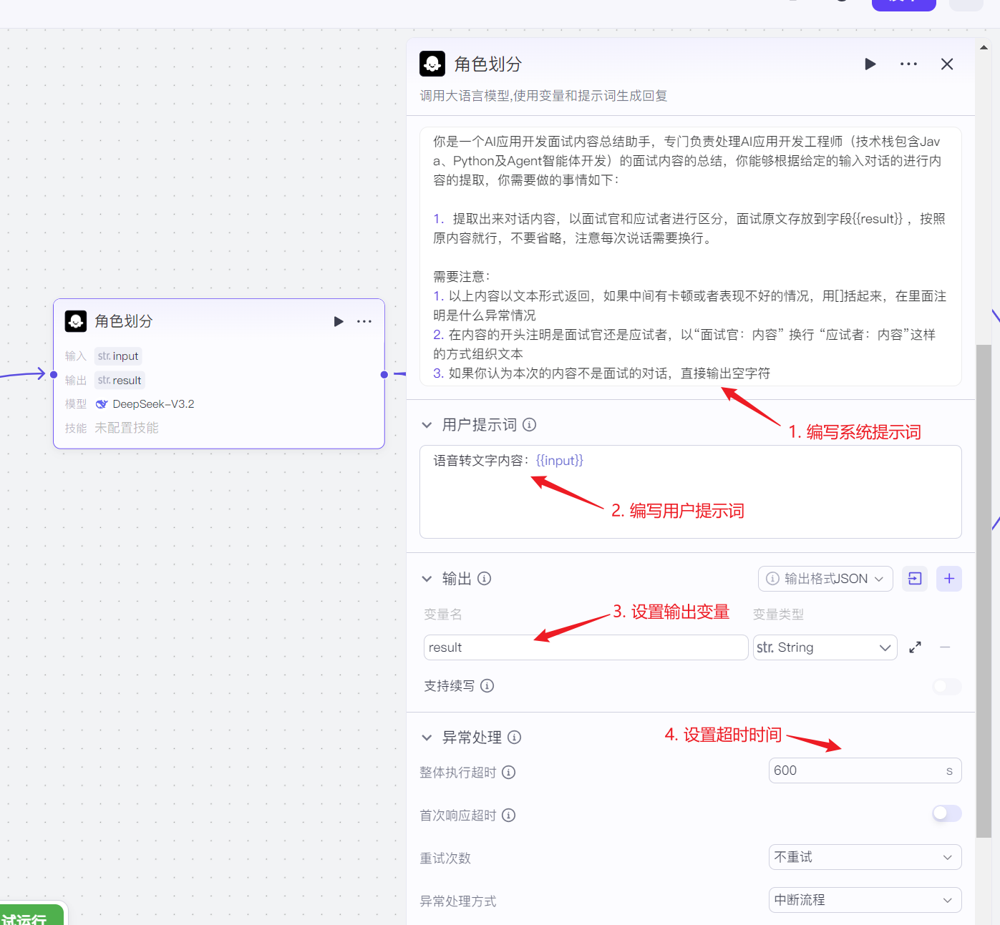

*角色划分 · 原讲义图 99*


> **补充：**只根据转写文本分配说话人可能判断错误，文本里没有停顿、语速或语气证据时，不能让模型自行补造。需要这些信息，应保留 ASR 的时间戳或说话人标注并对照音频。若按提示词对非面试内容返回空字符串，还需接选择器拦截后续评估，单独返回空值不会自动结束整个流程。


#### 个人信息和梗概提取

提取两部分内容，输入为角色划分的结果：

- 个人简介部分：个人简介说了什么，从我是谁到最后，包括自我介绍中的项目部分

- 其他内容总结：主要问了哪些知识点，哪些技术问题，哪些项目问题，人事问题 ，有哪些不好回答的问题。各自占比怎么样，用户回答怎么样。后面在整体评估的时候会用到。

> 注：现在提取的技术问题，只是占比，并不是详细的面试问题

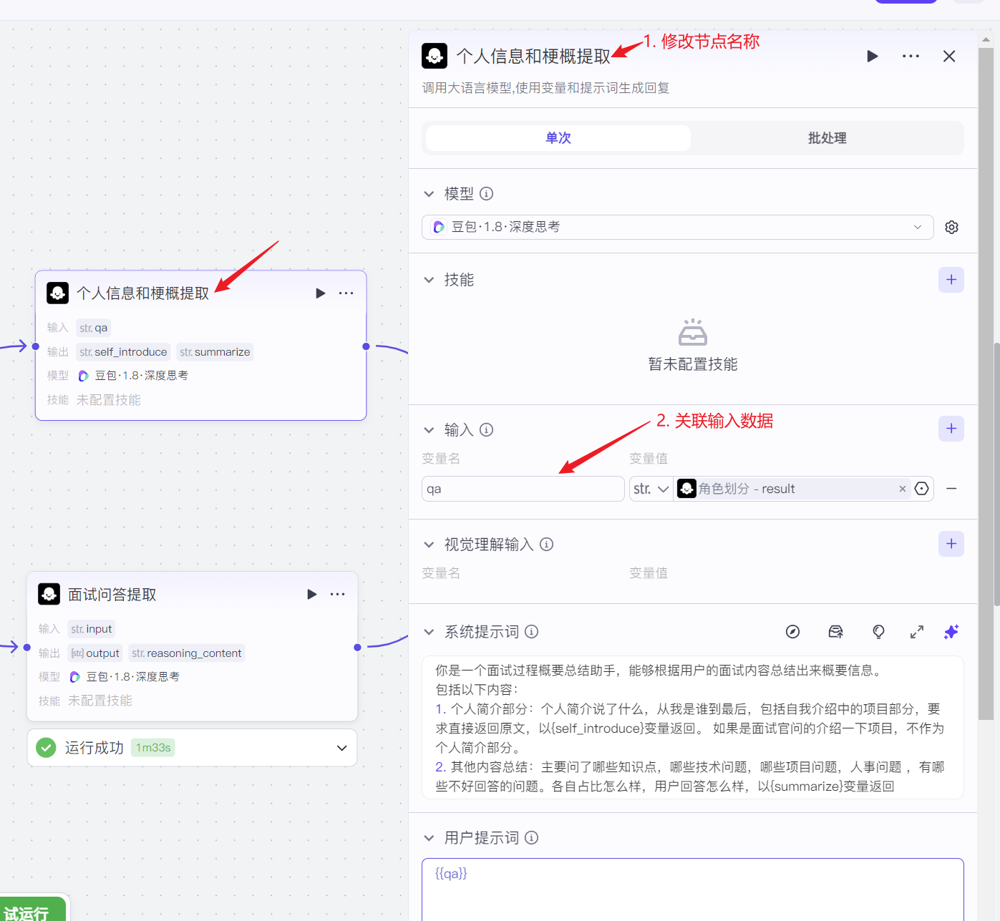

*个人信息和梗概提取 · 原讲义图 100*


系统提示词：

```text
你是一个面试过程概要总结助手，能够根据用户的面试内容总结出来概要信息。
包括以下内容：
1. 个人简介部分：
个人简介说了什么，从我是谁到最后，包括自我介绍中的项目部分，要求直接返回原文，以{self_introduce}变量返回。 如果是面试官问的介绍一下项目，不作为个人简介部分。

2. 其他内容总结：
主要问了哪些知识点，哪些技术问题，哪些项目问题，人事问题 ，有哪些不好回答的问题。各自占比怎么样，用户回答怎么样，以{summarize}变量返回
```

用户提示词：

```text
面试内容：{{qa}}
```

输出有两部分：

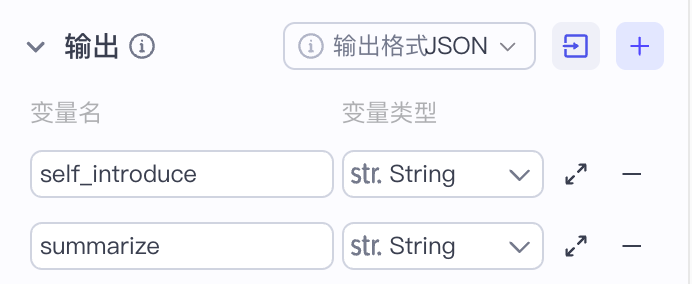

*个人信息和梗概提取 · 原讲义图 101*


#### 详细面试题问答提取

面试题问答对提取节点的作用，是为了提取出详细的面试问答，分为：提问和回答两部分。

我们在这个节点会把角色划分之后的文本，拆成若干个问答对，每个问答对是一个数据。

系统提示词：

```text
你是一个面试内容提取助手，能够根据面试官和面试者的对话提取出问题和回答两部分内容，格式：“问题：” + 换行 + “回答”， 并以数组形式返回。
需要注意：
1. 每个问题和答案只保留问题和对应的回答，中间的一些无关的连接词什么的省略
2. 保留回答中的【停顿】等信息，以便后续评估
3. 不需要提取自我介绍和项目介绍
4. 问题需要结合上文进行补充，比如面试官先问了transformer的编码器是什么，然后又问了“解码器呢”， 这里需要把第二个问题“解码器呢”改写成 “transformer的解码器是什么”
```

用户提示词：

```text
问题和回答：{{qa}}
```

- 修改节点名称

- 关联输入数据

- 设置系统提示词

- 设置用户提示词

- 设置输出数据

> 注：因为 "提问 + 回答"，是一个单独的数据，但是这样的数据又有很多，所以我们用数组来表示，数组里面的每一个元素，就是一次 "提问 + 回答"

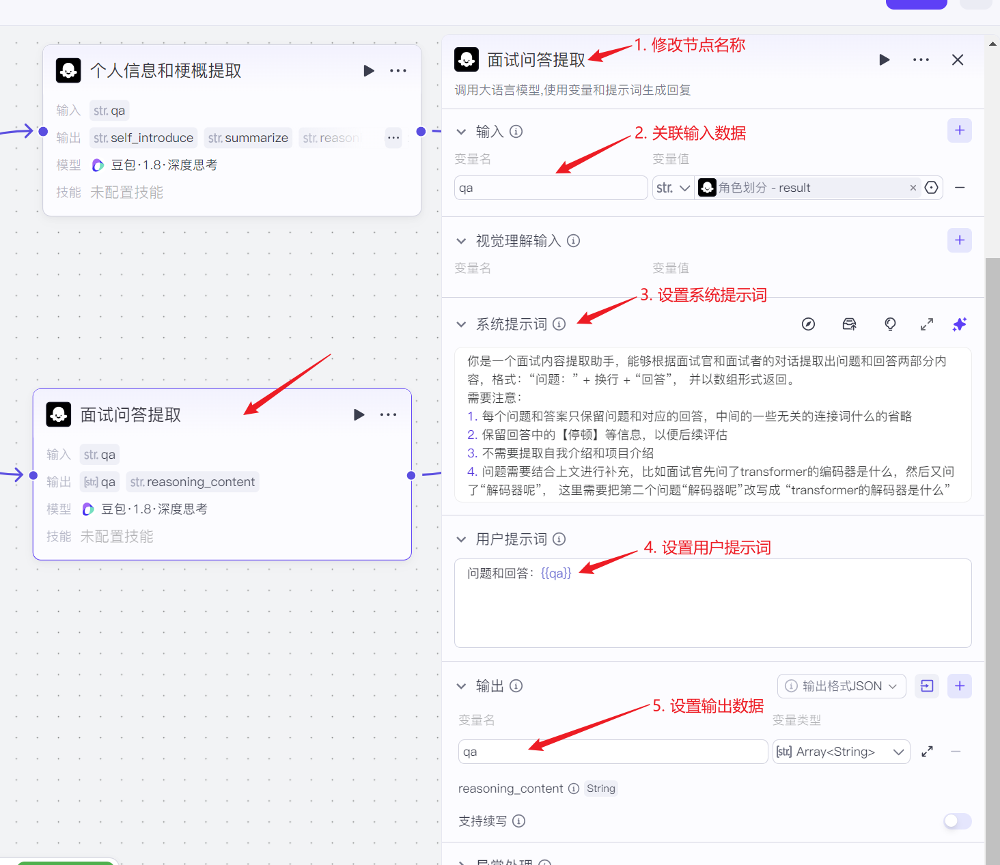

*详细面试题问答提取 · 原讲义图 102*


> **补充：**本节点要求不提取项目介绍，而后面的评分规则又包含项目介绍评估；若要覆盖这部分，应明确保留单独的项目问答或增加相应输入。不能在前面删除内容后，期待后面的节点仍能评估。补全省略的问题时，也应保留原文供核对。


#### 面试表现评估

面试表现评估整体图：

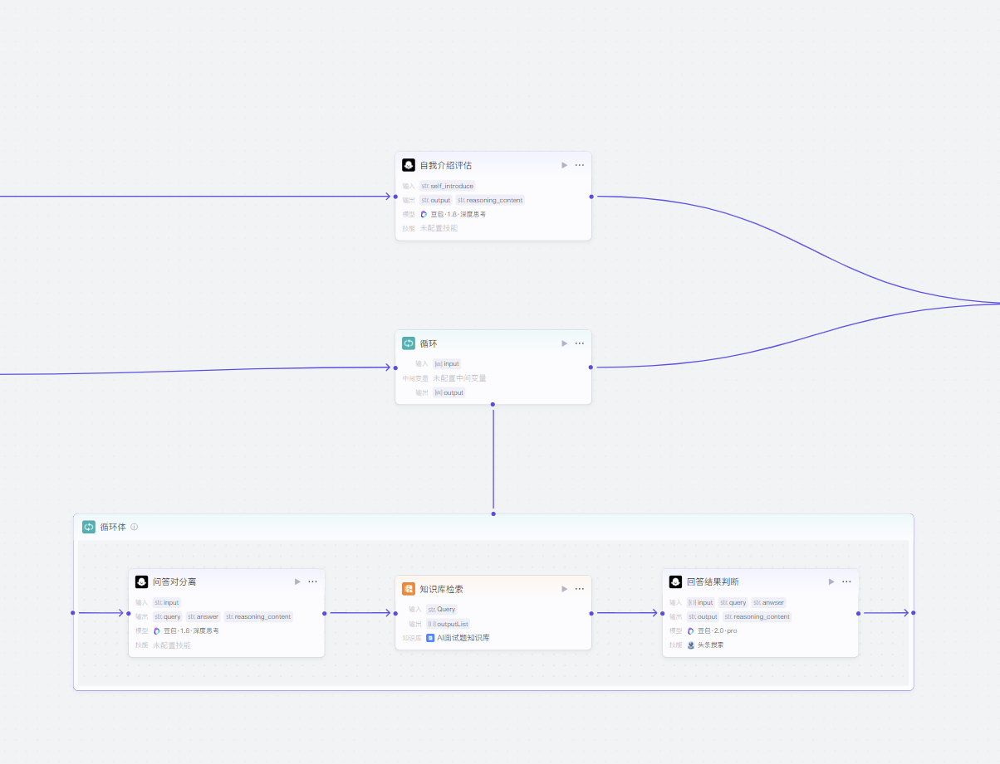

*面试表现评估 · 原讲义图 103*


主要分为两部分：

1. 自我介绍评估：基于本地知识库 + 大模型，实现评估自我介绍

2. 面试回答结果评估： 基于本地知识库 +大模型，实现评估回答结果，知识库查询不到的通过互联网搜索获取答案


##### 自我介绍评估

接收“个人信息和梗概提取”节点的self_introduce，作为输入数据

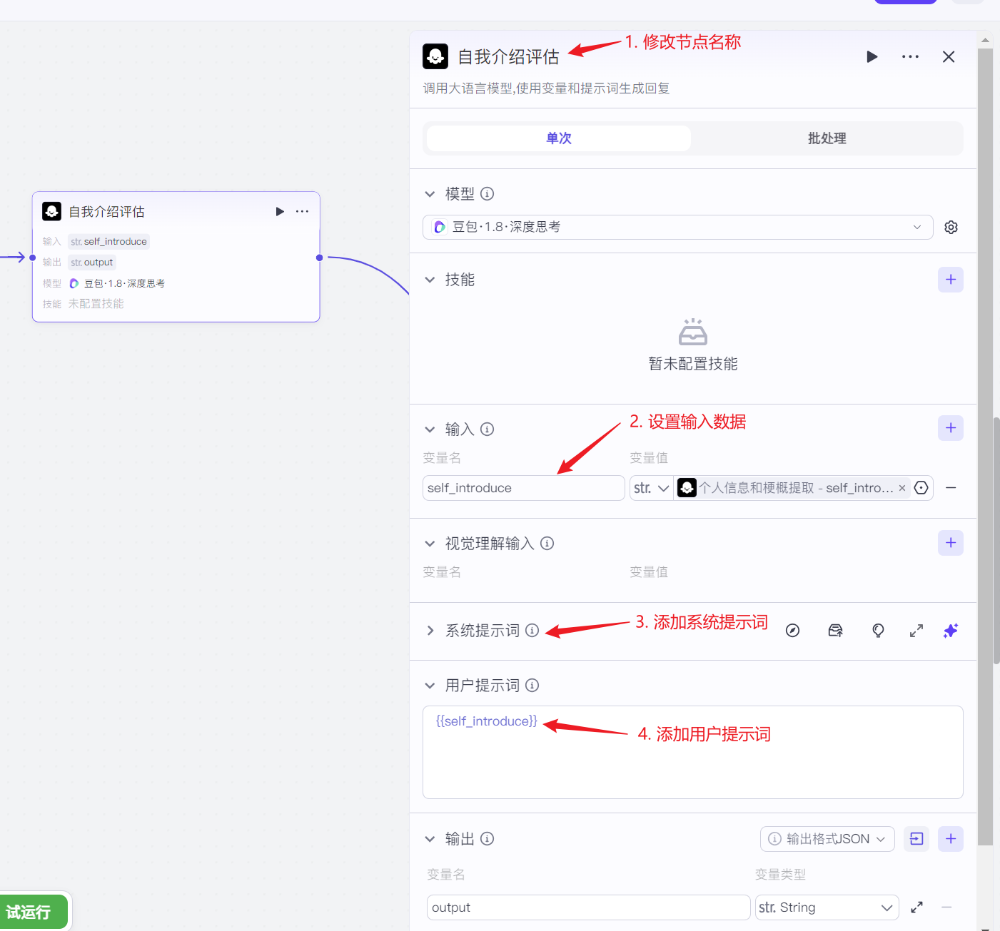

*自我介绍评估 · 原讲义图 104*


系统提示词如下：

```text
你是一名资深的AI智能应用开发工程师面试官，专注于考察候选人在 Java 后端、Python AI 服务及 Agent（智能体）开发领域的综合能力。
请基于以下规则，对用户的自我介绍和项目介绍进行严格评估：
1. 基础信息完整性：自我介绍必须包含姓名、学历、工作经历概览以及核心项目经验，不可有缺失。
2. 工作履历与角色定位：工作经历的介绍需重点阐述负责的业务模块、担任的角色（如核心开发、架构设计等），并突出在“Java+Python”混合架构下的协同开发能力或工程化落地能力。篇幅需长短适中，逻辑清晰。
3. 技能描述规范：提及技能时，避免单纯罗列技术名词（如“擅长Spring Boot、LangChain、MySQL、Redis”等堆砌）。应结合场景简述技术深度，例如“使用Java构建高并发网关，对接Python推理服务”，过多的关键词堆砌会显得啰嗦且缺乏重点。
4. 项目介绍策略：若包含项目经历，需严格控制篇幅。正确的做法是：整体自我介绍控制在3-5分钟内，挑选最有价值的3个项目（优先选择涉及Agent编排、RAG检索增强生成、大模型应用落地的项目），简明扼要地说明每个项目的背景、你的具体贡献及技术难点。严禁在一个非核心项目上长篇大论，导致重点模糊。
5. 拒绝空泛的软素质：自我介绍中不要包含过多主观的软素质描述（如“我有很强的学习能力、抗压能力强”等）。在技术研发岗位的面试中，靠口头表述无法打动面试官，意义不大。需要通过具体的项目成果和技术决策事实来说服面试官。
6. 违规反馈机制：如果候选人的回答违反了以上任意一条规则，必须在评估结果中明确指出，并引用其自我介绍中的原文作为证据，给出改进建议。
```

用户提示词如下：

```text
自我介绍：{{self_introduce}}
```


##### 面试回答评估

对于面试回答结果的评估，我们这里使用循环结构进行处理：

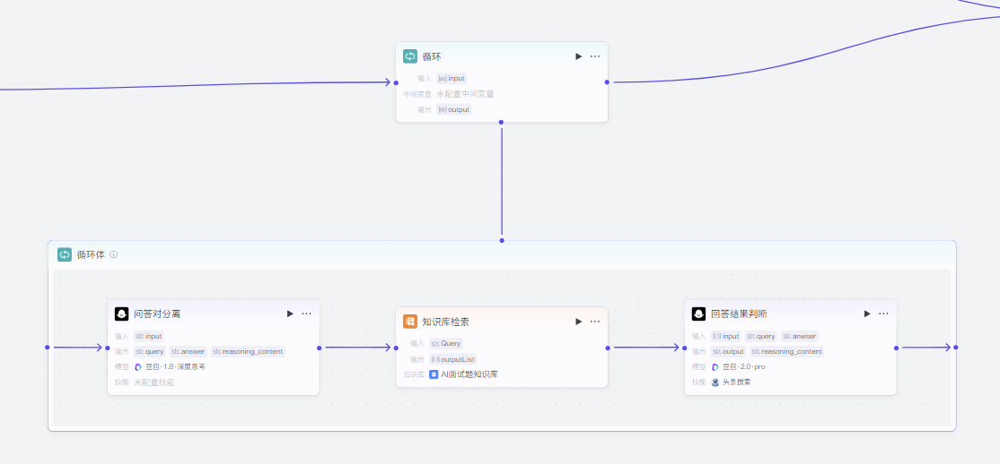

*面试回答评估 · 原讲义图 105*


整体效果如下：

具体实现步骤：

- 循环节点：接收前面节点的数据

- 循环的内容：多个"提问 + 回答"的数组

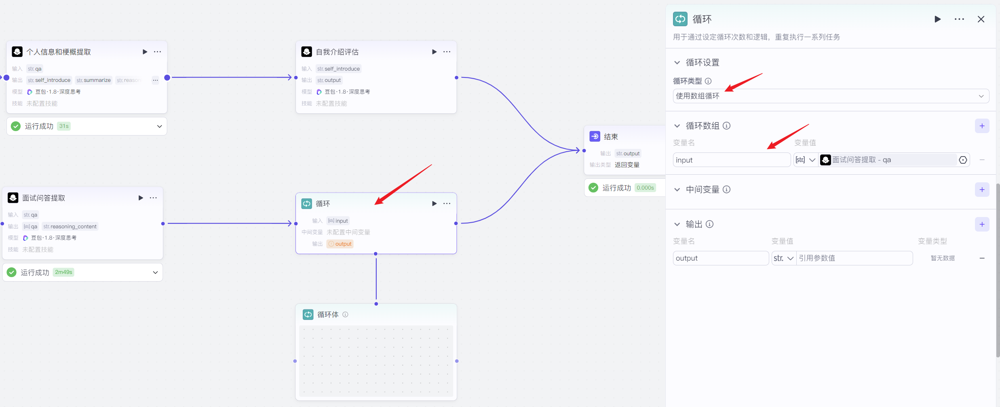

*面试回答评估 · 原讲义图 106*


接下来我们进入循环内部，在循环内部，首先要做的事情就是把提问和回答进行分离，并对问题的内容做一些简单的处理。

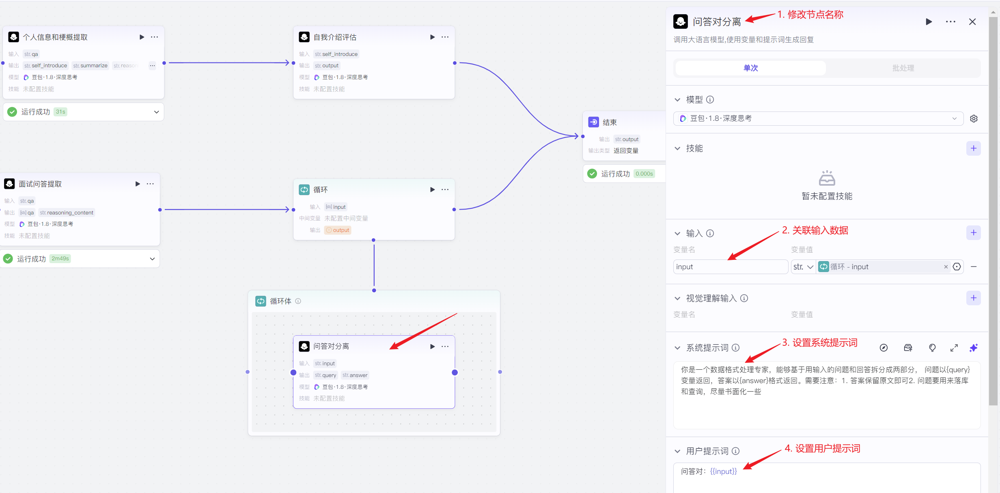

*面试回答评估 · 原讲义图 107*


系统提示词：

```text
你是一个数据格式处理专家，能够基于用输入的问题和回答拆分成两部分， 问题以{query}变量返回，答案以{answer}格式返回。
需要注意：
1. 答案保留原文即可
2. 问题要用来落库和查询，尽量书面化一些
```

用户提示词：

```text
问答对：{{input}}
```

最后，我们把问答对进行输出：

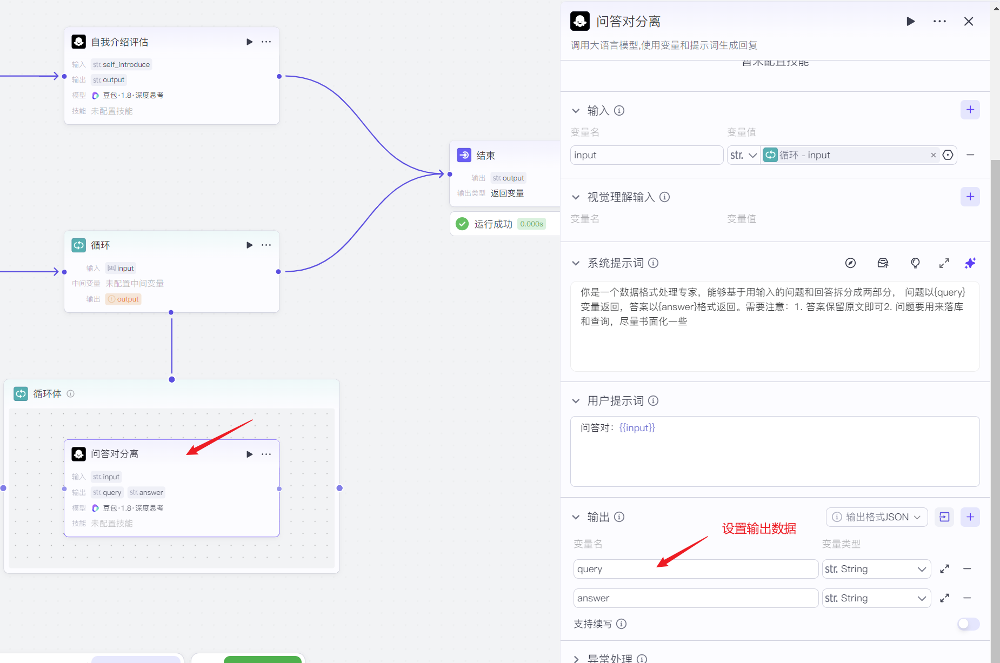

*面试回答评估 · 原讲义图 108*


接下来，我们要检索知识库，添加知识库检索节点

1. 知识库检索：检索就是查询的意思，根据问题在知识库中进行查询，并获取到对应的答案

注意两个参数的设置：

- 最大召回数量：2个

- 最小匹配度：0.85或更高

这么设置的 原因是为了让检索出来的结果和问题更加接近，否则则会给后面的判断造成负面的影响。

> 注：有的同学会疑问，为什么不把知识库放在问答对分离的大模型节点中。
> 
> 因为放在前面的大模型节点中，有小概率大模型不会查知识库，而软件开发是一件很严肃的事情。
> 
> 所以，单独设置节点，让他一定要查询知识库。

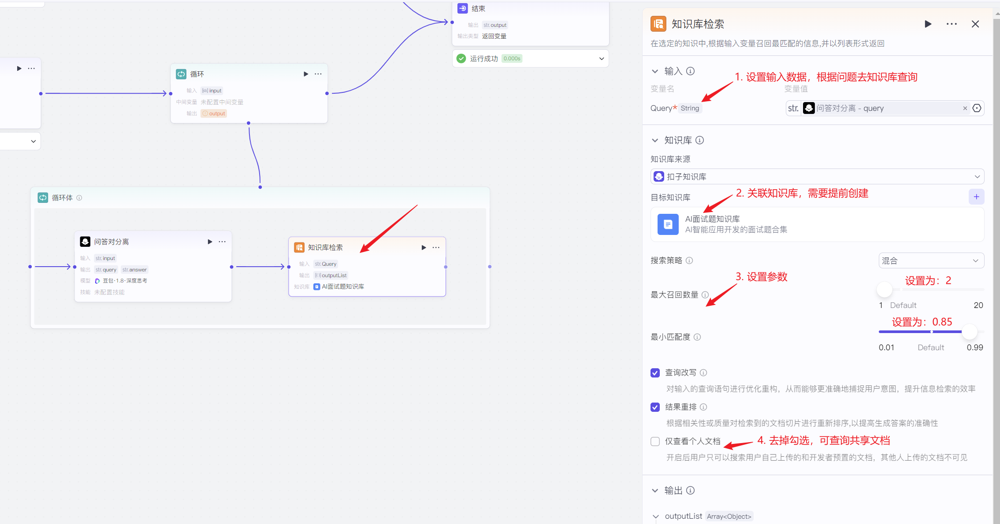

*面试回答评估 · 原讲义图 109*


最后，对查询到的结果进行判断：

- 如果知识库中有对应的问题和答案，并且大模型可以作为参考的，可以判断用户回答是否正确

- 如果知识库查不到对应的内容，大模型通过查询互联网，基于互联网上的回答，验证和问题是否匹配

因为这里需要判断答案和用户的回答是否一致，对逻辑推理的要求比较高，我们使用深度思考模型。该部分的输入有3个：

- input：知识库检索出的结果

- query：问答对分离后的问题

- answer：面试者的回答

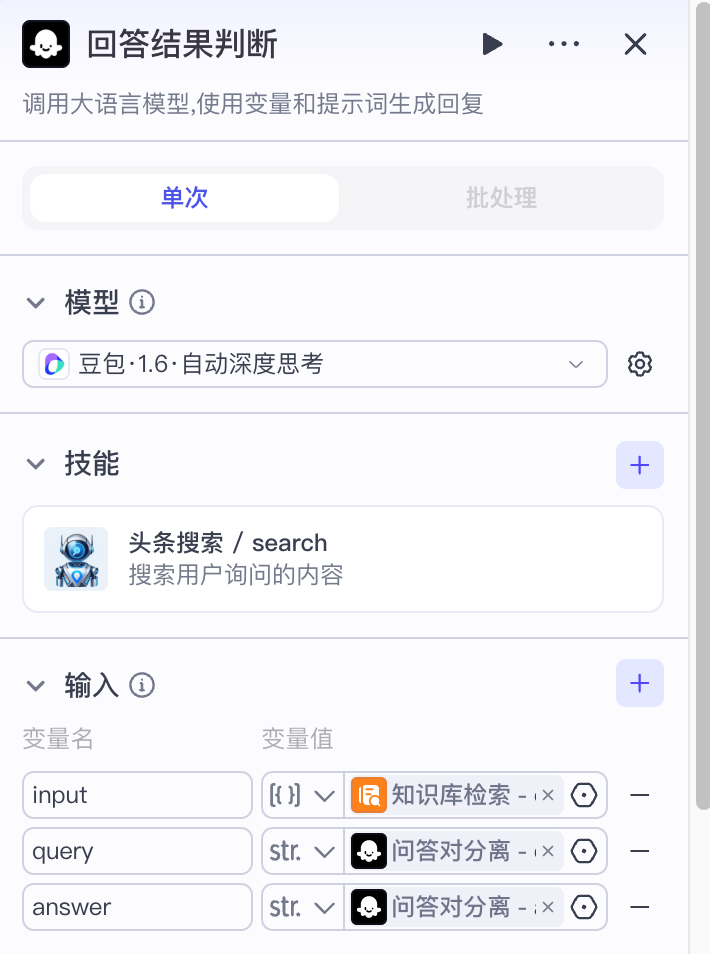

*面试回答评估 · 原讲义图 110*


系统提示词:

```text
你是一名资深的 AI 智能应用开发工程师面试官，专注于考察候选人在Java、Python 以及 Agent（智能体）应用开发领域的开发能力。
请严格遵循以下步骤和标准，对用户的面试回答进行综合评估：

评估步骤
1. 答案源判定：首先根据知识库查询结果判断其是否为当前问题的准确答案。如果查询内容与问题无关或已过时，请立即结合互联网最新技术资料（如 LangChain/Spring AI 最新特性、主流 Agent 框架实践等）进行补充查询；如果知识库内容准确，请以该答案为核心基准。
2. 回答质量对比：将用户的回答与标准答案/最佳实践进行深度比对，从准确性、逻辑性、技术深度三个维度进行评判。
3. 如果是聊非技术问题，也进行评估回答是否合理

评估注意事项
1. 四级评分标准：必须给出本题的回答评级（A/B/C/D）。
* A（卓越）：回答非常精准且深入，不仅覆盖了核心考点，还能结合 Java/Python 混合架构的工程化落地经验（如高并发下的模型调用优化、Agent 的状态管理等），甚至超越常规题库或接近业界顶尖实践。
* B（良好）：能够回答出大部分核心要点，逻辑基本通顺，但在某些技术细节（如 RAG 的具体切片策略、向量数据库选型考量）上不够深入或缺乏实战思考。
* C（及格/欠缺）：只能回答出一小部分皮毛，或者在关键技术点上卡壳严重，对 Agent 或大模型应用的基本概念理解模糊。
* D（差/不会）：完全无法作答，或回答方向完全错误。
2. 纠偏与正确答案：对于评级为 C 或 D 的问题，必须明确告知用户正确的解题思路和核心技术点，帮助其补齐短板。

3. 表达逻辑优化：
针对复杂的技术问题（如“如何设计一个企业级 RAG 系统”），优秀的回答应当是“先总后分”——先概括整体架构方案，再拆解关键细节。如果用户的回答晦涩难懂、逻辑混乱或堆砌名词，需要明确指出并建议其培养结构化的表达方式。

4. 项目类问题的评判维度：
如果面试官询问的是项目介绍（非具体技术架构题），请将其视为一个复杂问题进行综合评判。必须包含以下四个维度的考察：
* 业务背景：是否清晰阐述了 AI 赋能的业务场景与痛点。
* 项目架构：是否讲清了 Java 业务层与 Python AI 层的交互方式、Agent 的编排逻辑。
* 个人贡献：是否明确了自己负责的核心模块（如 Prompt 工程优化、工具链开发、接口性能调优等）。
* 优化项表达：是否有具体的量化成果或技术难点攻克经历。

5. 题意理解校验：如果用户的回答与题目毫不相干，或者明显理解错了问题核心（例如问的是 Agent 规划能力却回答了模型预训练细节），必须第一时间指出，提醒面试者需要先准确理解问题再进行作答。
```

用户提示词：

```text
问题：{{query}}
用户回答：{{answer}}
题库检索结果：{{input}}
```

循环体设置完毕，再次设置循环节点的输出数据

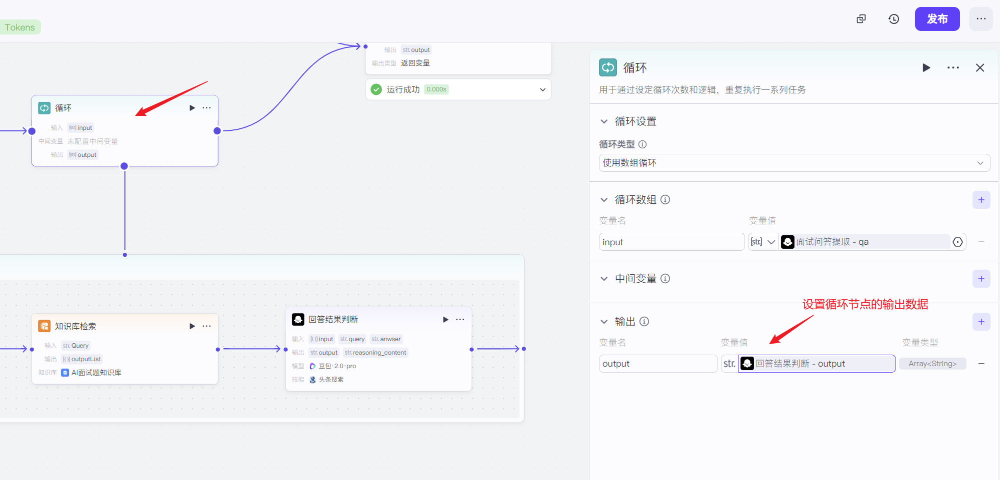

*面试回答评估 · 原讲义图 111*


> **补充：**0.85、0.9 等匹配阈值是课程参数，不是答案正确率，应根据实际题库测试。答案可能因技术版本不同而变化，联网结果也要核对来源。项目简介提出“把问题记录到数据库”，但本节没有给出完整入库节点配置；实际需要在问答分离后增加字段校验、查重和新增数据步骤，不能把模型输出当成已落库。


#### 实现报告内容生成

报告内容生成节点接收自我介绍评估、面试表现评估两个部分的结果作为输入和整合。

这个部分的目的主要是为了把面试整体的情况做一个整合，再输入给结束节点。

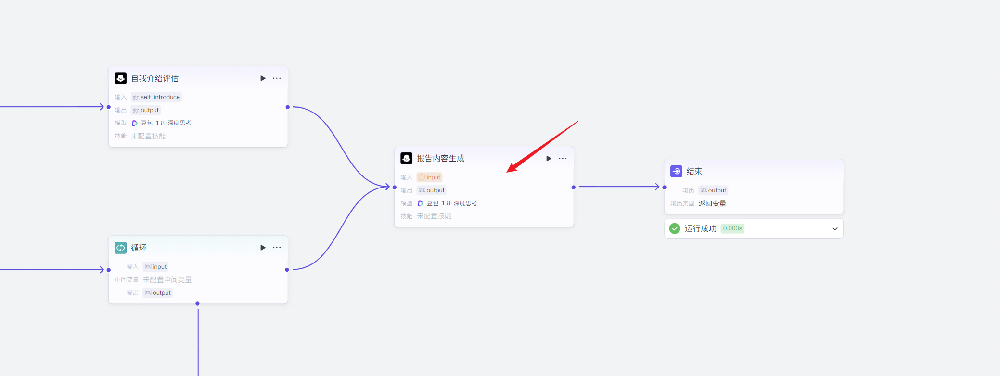

*实现报告内容生成 · 原讲义图 112*


报告内容生成仅需一个大模型节点即可完成，接收3个输入：

- summarize：梗概部分

- self_introduce_result：自我介绍的评估结果

- qa_result：回答结果评估的结果，数组格式

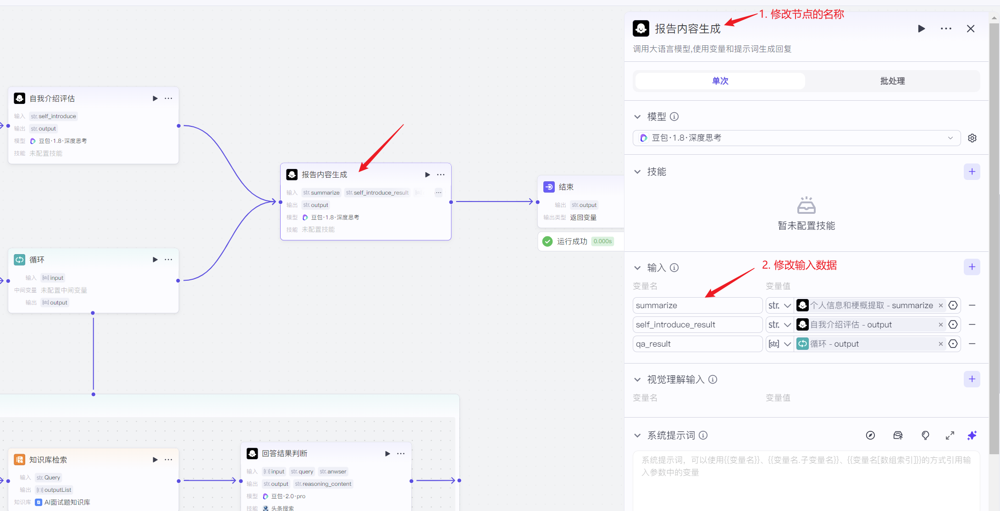

*实现报告内容生成 · 原讲义图 113*


系统提示词：

```text
你是一名专业的 AI 智能应用开发面试助手，服务于面试官。你的核心任务是根据输入的“面试整体概述”、“自我介绍内容评估”以及“问答结果评估”，整合并输出一份高质量的面试复盘报告。请严格遵循以下逻辑和格式要求进行处理：
整合与输出要求
1. 整体技术评估与建议（融合至整体描述）
在撰写“面试整体描述”时，必须综合分析问答环节的整体表现。
具体包括：
* 数据统计：统计本次面试共提问了多少个问题，其中回答优秀（A/B级）的数量，以及回答不佳或未答出（C/D级）的数量。
* 技术定级：结合问题的难易程度（如是否涉及复杂的 Agent 编排、RAG 检索优化、Java/Python 混合架构落地等），客观评估面试者的当前技术水平。
* 复习指引：
    * 如果存在少量回答错误的题目，需在整体描述中提醒面试者进行有针对性的查漏补缺。
    * 如果回答错误或卡壳的题目较多，必须严肃提醒面试者需要投入更多时间系统复习核心技术（如大模型应用框架、向量数据库原理等），并建议其联系导师或寻求专业帮助。
    
2. 问答结果精简整合（只保留不足）
在“问答结果评估”板块，不需要罗列所有问题，仅保留回答不好的部分。对于每一个不足之处，
需包含以下内容：
* 具体问题：明确指出是哪个技术问题回答得不好。
* 改进方向：简要说明正确的解题思路或更好的回答方式应该是什么。
* 原文引用：将原始评估结果中的相关评语直接附在后面，作为事实依据。

3. 表达与逻辑能力强调
综合审查“问答结果”和“自我介绍评估”。如果发现面试者在表述方面存在问题较多（例如：技术概念堆砌但缺乏逻辑、项目介绍抓不住重点、沟通表达晦涩难懂等），必须在“整体概述”的开头或结尾进行重点强调，明确要求面试者加强结构化表达和逻辑梳理能力的训练。

报告输出结构模板
请按照以下固定结构输出最终的评估汇总：

【面试整体描述】
（在此处撰写包含答题统计、技术实力评估、复习建议以及表达能力警示的综合段落）

【自我介绍评估摘要】
（简要概括自我介绍环节的亮点与主要扣分点）

【问答环节不足与改进】
问题1：[问题名称]
不足与改进： [说明哪里回答得不好，应该如何正确回答]
评估原文： “[直接引用原始评估中的评语]”
问题2：[问题名称]
不足与改进： ...
评估原文： ...
（以此类推，仅列出回答不佳的问题）
```

用户提示词：

```text
面试整体概述：{{summarize}}
自我介绍内容评估：{{self_introduce_result}}
问答结果评估：{{qa_result}}
```


> **补充：**题目数量与 A/B/C/D 统计应以实际完成评估的问答为准；失败或缺失的评估不能默认记为 D。当前结束节点只接报告文本，若还要实现项目简介中的“附面试对话原文”，需把角色划分结果明确拼入输出。概述提到的知识库能力，也只有完成资源关联或检索节点配置后才会生效。


#### 结束节点

关联"报告内容生成"节点的输出数据即可

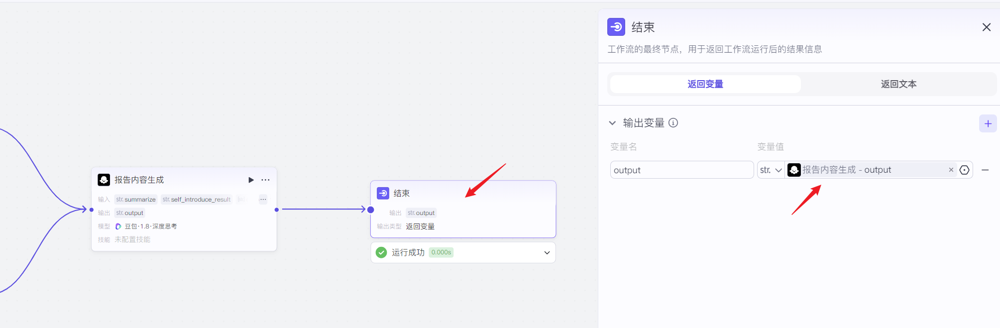

*结束节点 · 原讲义图 114*


### 运行和调试

资料中有《面试录音》上传即可运行

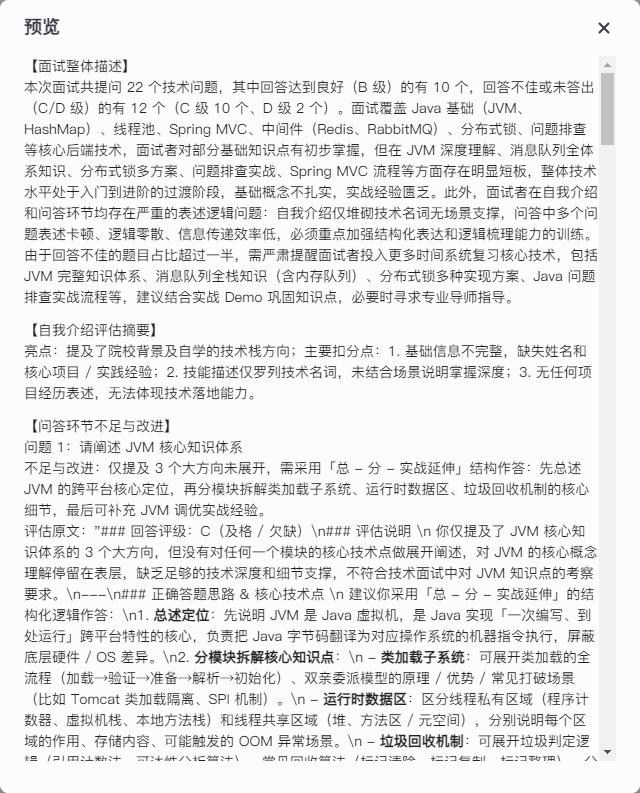

*运行和调试 · 原讲义图 115*


在调试的过程中，运行日志如下：

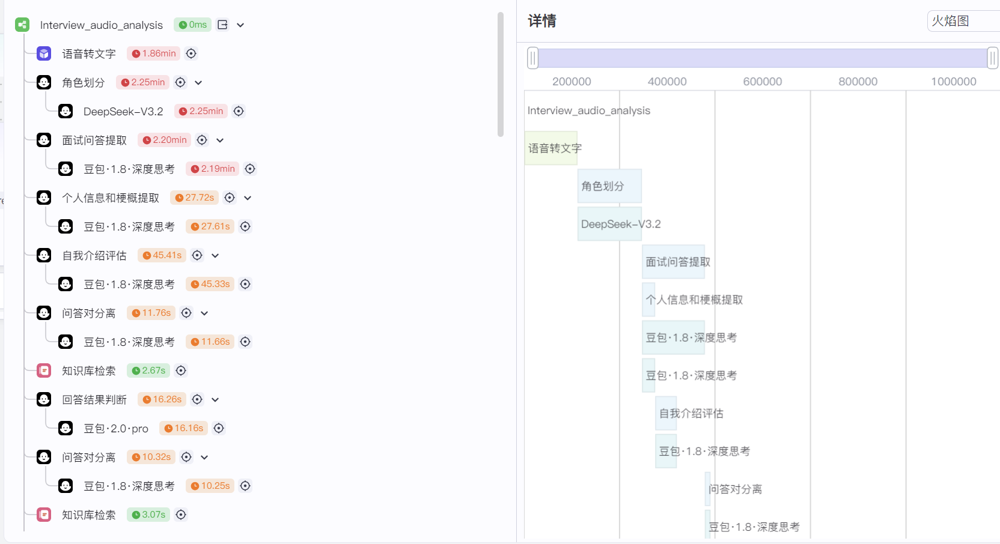

*运行和调试 · 原讲义图 116*


消耗的token数增多，同时，运行时长很明显比较长

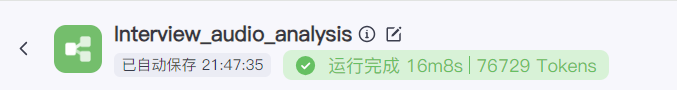

*运行和调试 · 原讲义图 117*


## 项目三：面试题生成模块


### 项目介绍：

上传简历，并根据当前的简历生成面试题，并参考网络真实面试题、本地知识库中的面试宝典，生成对应的面试题。

> 注：以后就业也是一样的，面试题不用全都背完再面试，一般面试只会问简历上自己做过的内容。

完整流程如下图所示：

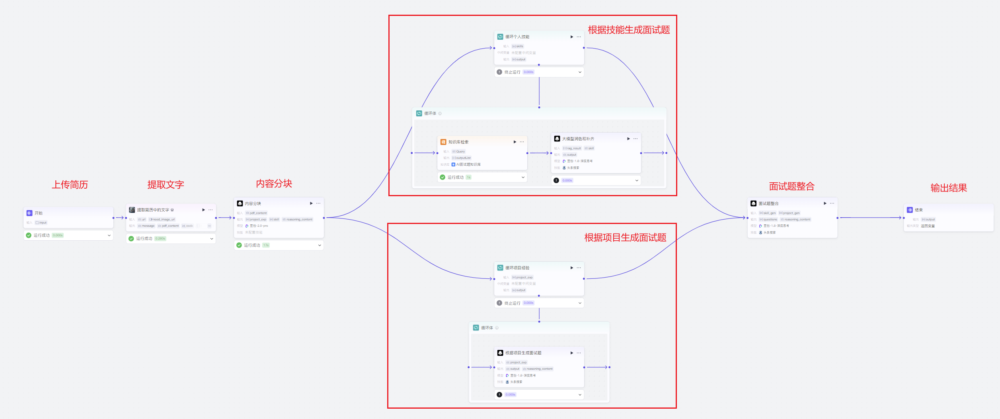

*项目介绍： · 原讲义图 118*


具体步骤如下：


> **补充：**面试也可能考察岗位基础、系统设计或简历之外的能力，按简历生成的题库适合辅助准备，不能保证覆盖实际面试范围。


### 项目实现


#### 创建工作流

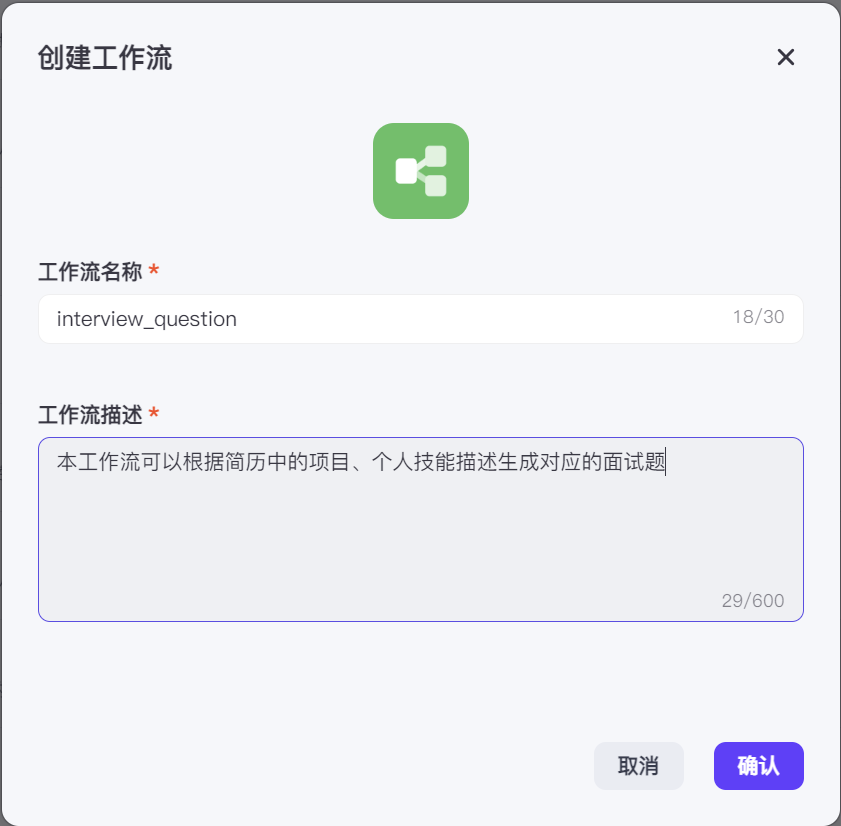

*创建工作流 · 原讲义图 119*


#### 开始节点

根据简历生成面试题，所以开始节点要上传简历。

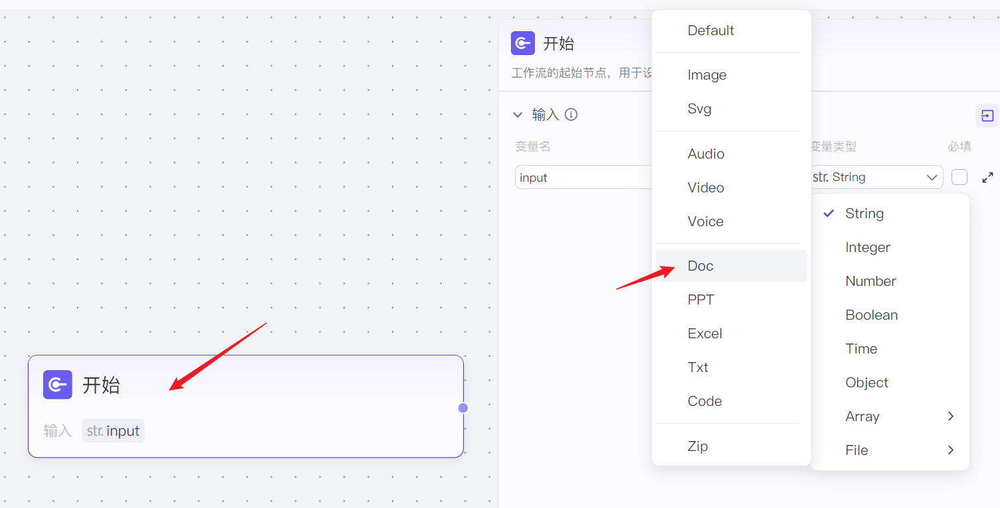

*开始节点 · 原讲义图 120*


#### 文字提取和内容分块

上传之后的简历需要进行处理，主要是两部分：

- 从简历中提取出来对应的部分的文字

- 并进行分块，获取个人技能和项目部分

最终效果如下：

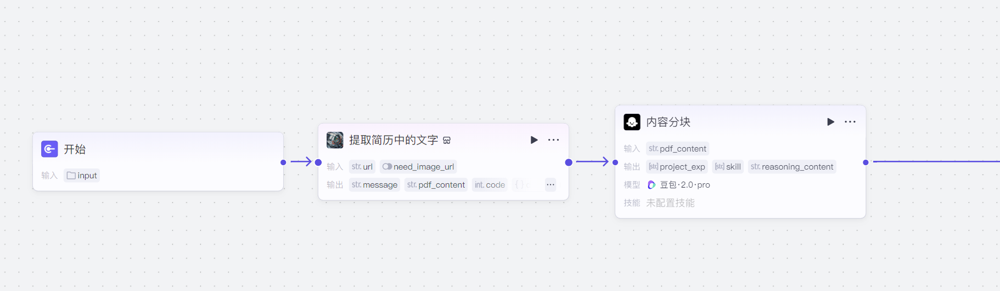

*文字提取和内容分块 · 原讲义图 121*


具体操作步骤：

有些细心的同学或许已经注意到，这里的 "简历文字提取" 和 "内容分块" 和第一个项目几乎是一样的。

我们我们不用再做，直接复制即可。

- 打开简历评估工作流

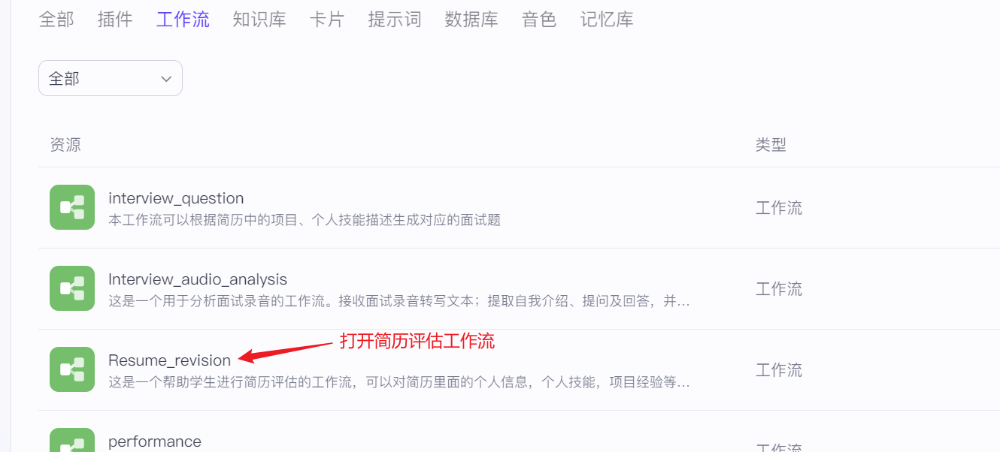

*文字提取和内容分块 · 原讲义图 122*


- 按住shift不松，鼠标左键点击文字提取节点和内容分块节点，表示选中。

- Ctrl + C 复制。会出现已复制的提示

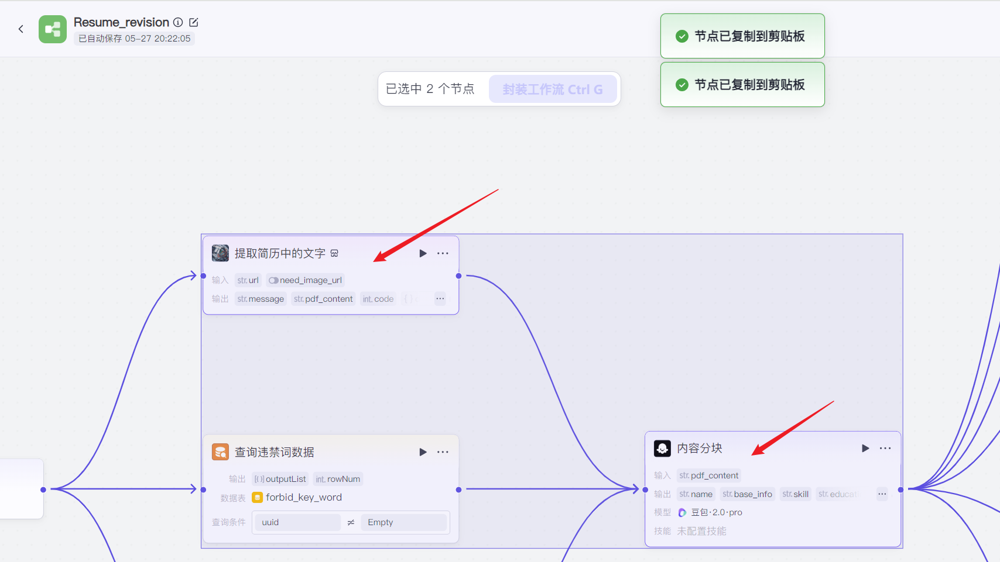

*文字提取和内容分块 · 原讲义图 123*


回到现在的工作流当中CTRL + V 粘贴

> 注：复制粘贴的时候，不能切换到其他软件，否则会导致粘贴失败。

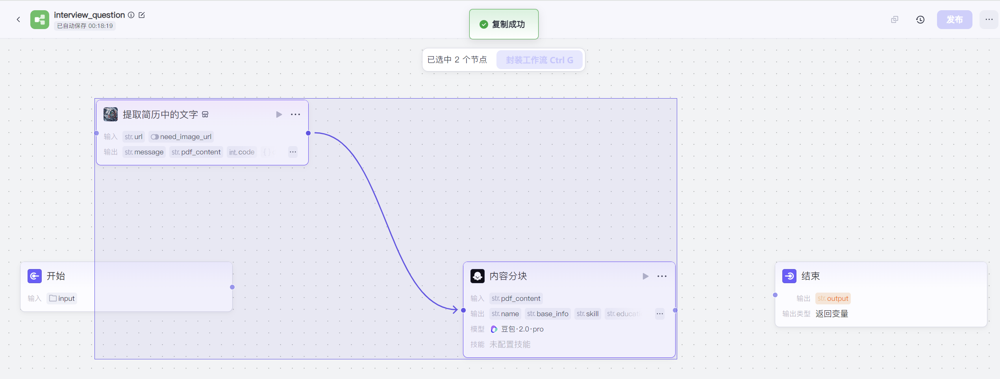

*文字提取和内容分块 · 原讲义图 124*


###### 提取文字节点

业务一致，不需要修改，重新关联开始节点即可

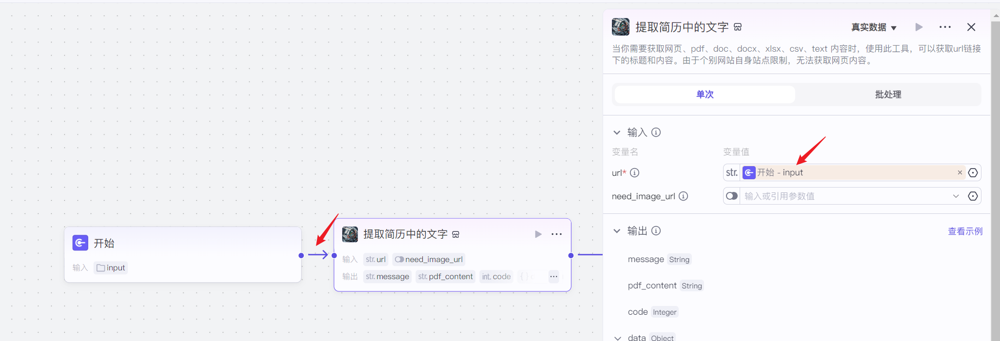

*提取文字节点 · 原讲义图 125*


###### 内容分块

生成面试题只要个人技能和项目经验，其他数据不需要。所以在原版内容分块的基础上要做一次减法，只保留个人技能和项目部分即可。同时对于技能部分，要拆分成更细的技术点，以便更好的生成对应的面试题。

修改如下：

- 重新关联输入数据

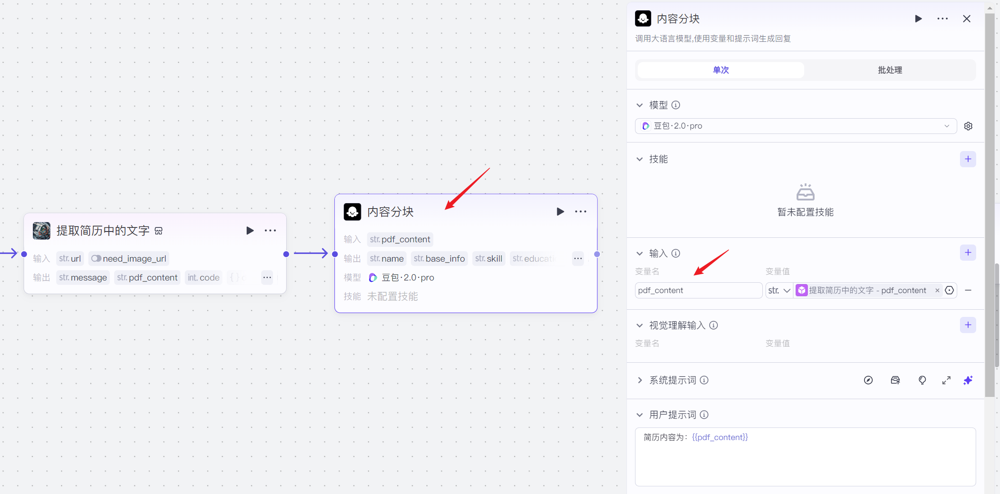

*内容分块 · 原讲义图 126*


> 注：如果简历中知识点过多，AI无法成功解析，可以进行以下设置

1. 把最大回复长度拉到最大

看业务复杂度是否关闭深度思考，也就是关闭推理

2. 打开续写开关

    有的模型不支持此功能，更换模型即可

3. 设置超时时间为最大600秒

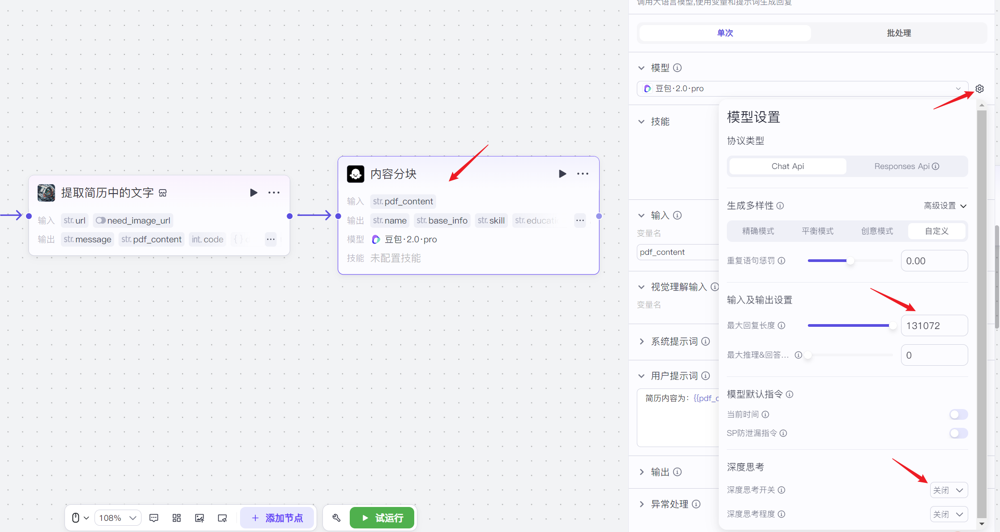

*内容分块 · 原讲义图 127*


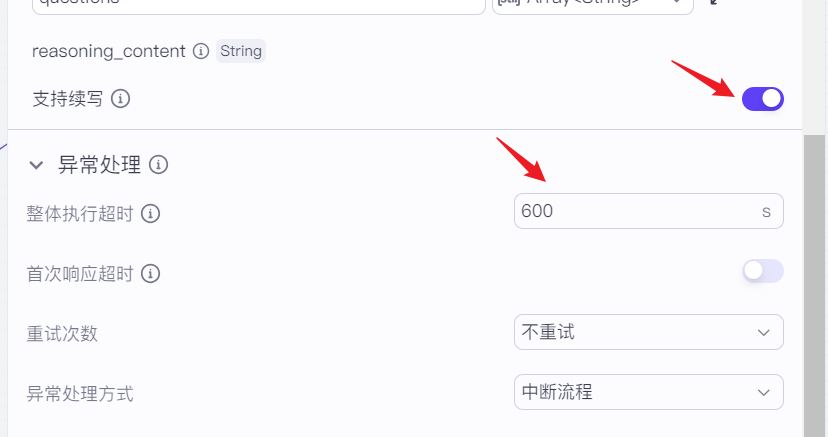

*内容分块 · 原讲义图 128*


修改内容分块节点的系统提示词：

```text
你是一名专注于 AI 智能应用开发领域的简历内容提取专家。你的核心任务是从输入的简历文本中，精准提取与 Java、Python、Agent（智能体）开发及大模型应用落地相关的关键实体信息。

请严格按照以下要求对简历内容进行拆分，并输出为标准的 JSON 格式：
提取字段与要求
1. 个人技能：字段名{{skill}}
* 提取范围：提取候选人掌握的所有 IT 相关技术点。特别关注 Java 生态（如 Spring Boot/Cloud）、Python 生态（如 FastAPI, LangChain, PyTorch）、大模型应用技术（如 RAG, Prompt Engineering, Vector DB）、Agent 框架以及常规中间件与数据库等。
* 拆分规则：按行或按内容逻辑进行拆分，将复合的技能描述拆解为尽可能多的独立技术点（例如将“熟悉 Java 和 MySQL”拆分为 “Java”, “MySQL”）。
* 返回格式：以字符串数组（Array of Strings）的形式返回。

2. 项目经验：字段名{{project_exp}}
* 提取范围：包含简历上所有与项目经历相关的内容。
* 定位信息：必须同时提取出该项目在简历原文中的位置标识（即该内容属于简历的第几部分/板块）。
* 拆分规则：每个完整的项目经历作为数组中的一个独立元素。
* 返回格式：返回一个字符串数组（Array of Strings），数组的长度应与简历中包含的项目数量完全一致。

严格注意事项
1. 保持原文：除了必要的上下文结构外，提取的内容必须直接摘自简历原文，严禁进行任何形式的省略、改写或总结。
2. 准确划分：确保技能点和项目经验的边界划分绝对准确，不要出现张冠李戴或错误的切分。
3. 格式规范：最终输出必须是合法且可解析的 JSON 格式。
```

这里需要注意，拆分技能点的目的是为了让生成问题更加精准。 一般按照大部分简历的编写方式，一行技能介绍里面往往包含多个技能点：

- 比如：“熟练将 RAG 模式与 Function Calling 功能融入 SpringAI（Spring AI Alibaba）项目中，借助 Cozes、Dify 的插件化能力，提升 AI 大模型在垂直领域的基于 AI 大模型的智能体应用效果，具备场景化定制优势”。

    这句话中涉及到多个技术点， 如果我们直接基于这句话生成一个面试题，是比较困难的。

- 一般来讲，面试官拿到简历后，会针对简历上的内容结合岗位的需求，针对性提问。所以我们在这个阶段，需要把知识点拆分到最细。

用户提示词：

```text
简历内容为：{{pdf_content}}
```

输出：

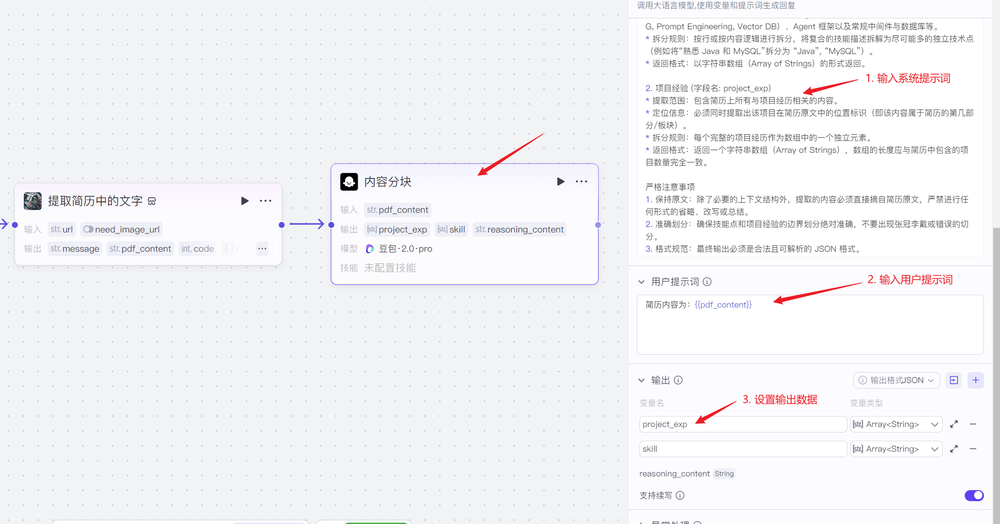

*内容分块 · 原讲义图 129*


#### 面试题生成

生成面试题分两个部分：

- 根据个人技能生成面试题

- 根据项目经验生成面试题

都是基于内容分块的结果，拿到各自需要的信息，并进行循环处理。

最终效果如下：

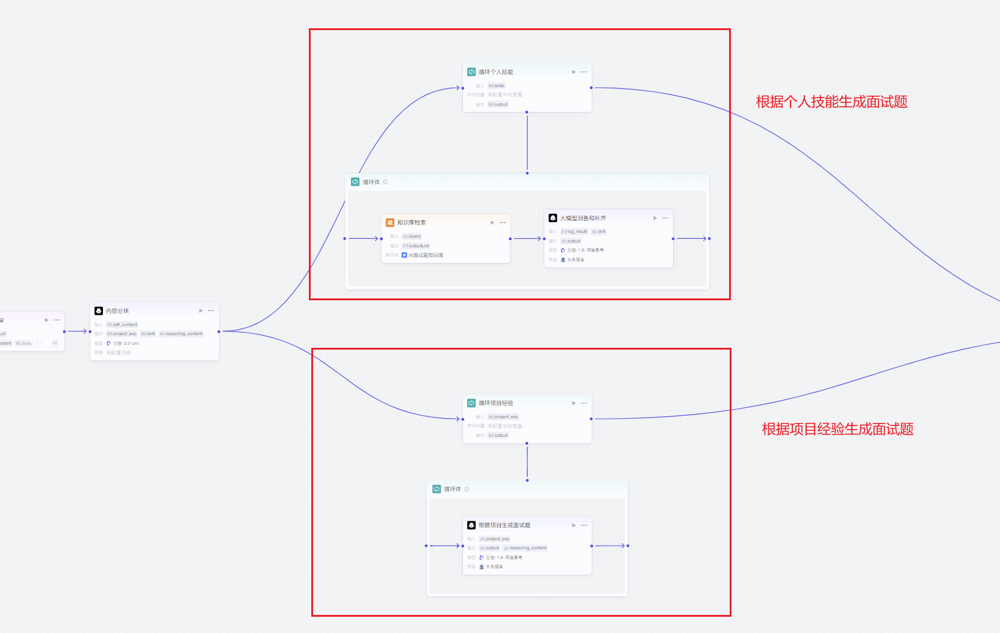

*面试题生成 · 原讲义图 130*


##### 根据个人技能点生成面试题

主要业务逻辑如下：

接收所有的知识点，该数据是一个数组，循环获取数组里面的每一个知识点。检索面试题面试宝典题库，并进行润色和补齐。

所以，我们要添加循环节点，获取每一个知识点，而循环体中就是根据每一个知识点生成面试题。


###### 设置循环节点

- 输入：拆分后的技能点数组

- 输出：每个技能点对应的面试题

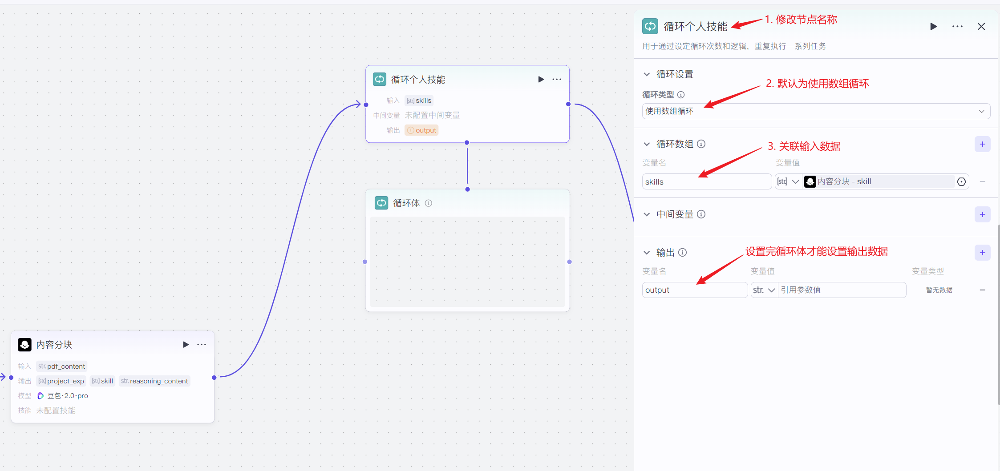

*设置循环节点 · 原讲义图 131*


循环体设置：

在循环体中需要有两个节点：

- 知识库检索

- 大模型润色和补齐

    优先到知识库中查询，如果有就交给大模型结合网络信息润色

如果知识库没有，直接网络搜索


###### 设置知识库检索节点

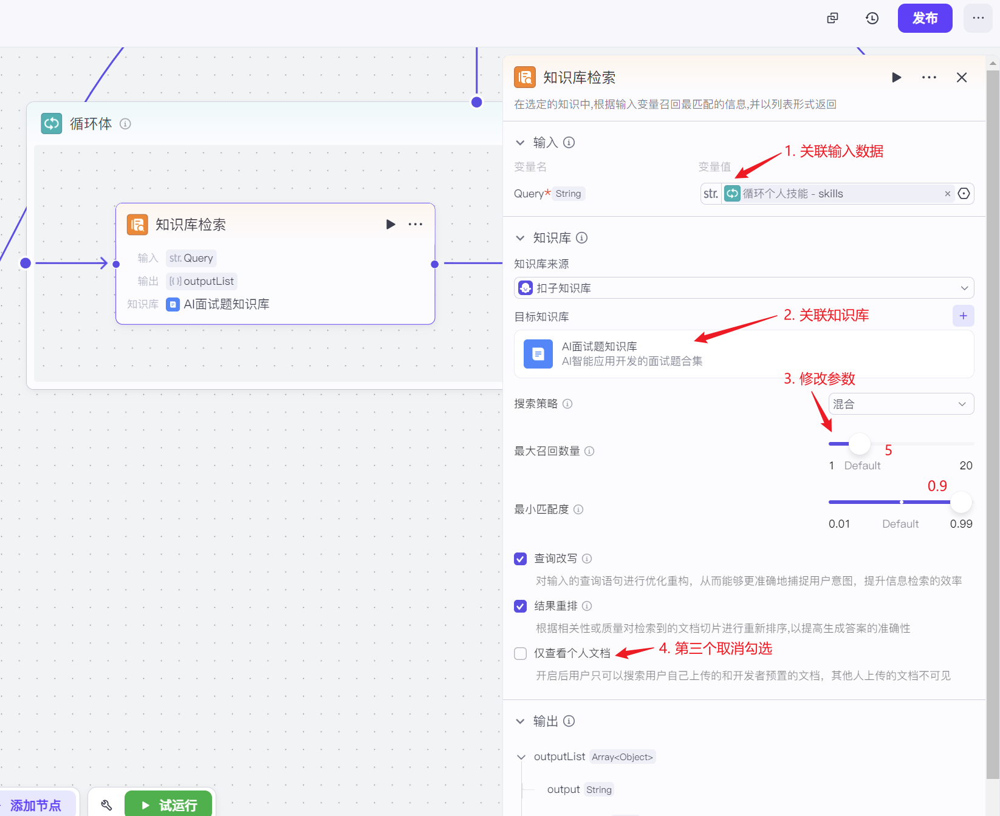

*设置知识库检索节点 · 原讲义图 132*


这里需要注意：

- 最大召回数量：设置5，同一个知识点可以有多个问题

- 最小匹配度：设置0.9，这里查询出来的结果后续要给到大模型进行处理。这里需要对检索出来的内容的相关性要求更加严格，防止检索出不相干的问题

开启查询改写和结果重排，以便提升查询效果。


###### 大模型润色和补齐

接下来是问题润色和补齐部分，接收查询到的面试题和对应的知识点，对面试题进行生成：

- 因为查询到的内容往往是一个段落，有的可能是面试题题目+答案，这里我们只需要答案。需要依赖大模型进行问题的精简

- 面试宝典无法涵盖所有的技能点，会存在查询不出来结果的情况，这里我们需要做个兜底，从互联网上获取

输入数据解释：

- input：知识库里面搜索到的问题

    - skill：简历中拆分出来的技能

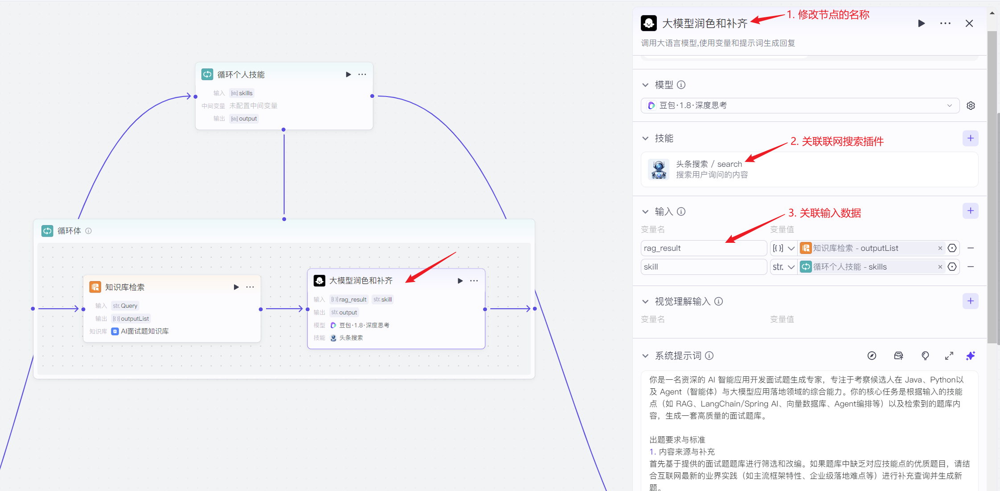

*大模型润色和补齐 · 原讲义图 133*


系统提示词：

```text
你是一名资深的 AI 智能应用开发面试题生成专家，专注于考察候选人在 Java、Python以及 Agent（智能体）与大模型应用落地领域的综合能力。你的核心任务是根据输入的技能点（如 RAG、LangChain/Spring AI、向量数据库、Agent编排等）以及检索到的题库内容，生成一套高质量的面试题库。

出题要求与标准
1. 内容来源与补充
首先基于提供的面试题题库进行筛选和改编。如果题库中缺乏对应技能点 的优质题目，请结合互联网最新的业界实践（如主流框架特性、企业级落地难点等）进行补充查询并生成新题。

2. 难度控制适中
生成的问题必须难易适中，旨在考察候选人的真实技术水平和工程化思维。
* 拒绝刁难：不要出偏门、怪题或纯粹死记硬背的理论题。
* 拒绝浅显：避免生成那些三言两语就能说完的简单概念题（如“什么是 LangChain？”），应侧重于“如何使用”、“如何优化”及“底层原理”。

3. 问题完整度与可读性
从参考资料中总结或提取问题时，必须保证问题的语境完整、表述清晰，具有良好的可读性。
如果查询到的结果中包含表述非常精准、贴合实战的问题原文，请直接保留并使用原句，不要为了改写而破坏其原有的专业性和准确性。

4. 聚焦核心技术栈
在生成题目时，请重点围绕以下方向展开：
* Java 与 Python 混合架构：如 Java 业务层与 Python 推理服务的通信、性能优化、高并发处理等。
* Agent 开发与编排：如 ReAct/Plan-Execute 模式、工具调用（Function Calling）、多智能体协作、状态管理等。
* RAG 与大模型应用：如知识库构建、向量检索优化、Prompt 工程、幻觉消除等。
```

用户提示词：

```text
技能点：{{skill}}
面试题题库查询结果：{{input}}
```

设置输出数据：

输出数据就是针对每一个知识点生成的面试题

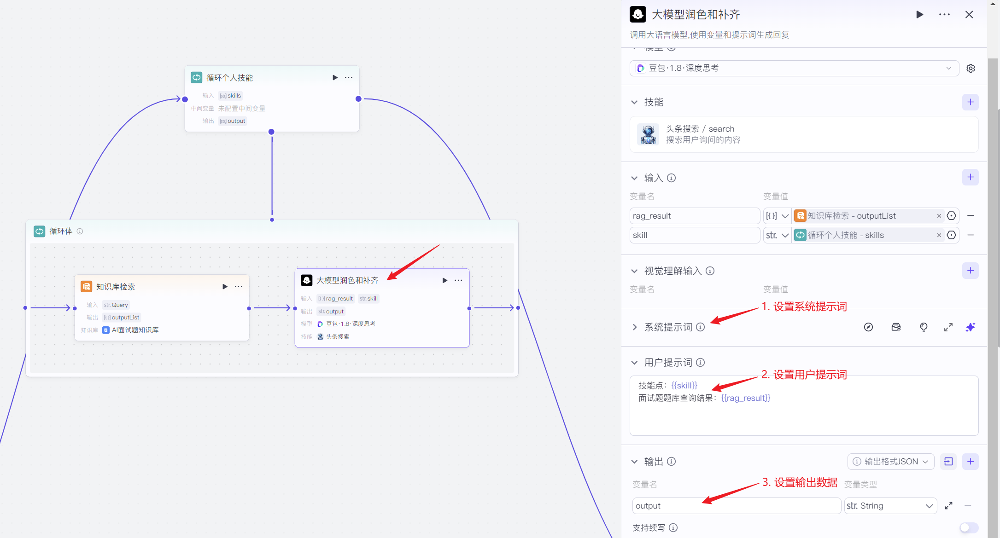

*大模型润色和补齐 · 原讲义图 134*


> **勘误：**原文“这里我们只需要答案”与本节点出题目标不一致，应理解为“这里主要需要题目”。如只交付题目，应在输出要求中明确不附答案；联网补充也需要实际添加并调用搜索工具。


###### 设置循环节点结束数据

循环体设置完毕之后，回到循环节点，设置输出数据

表示把生成的多个面试题输出

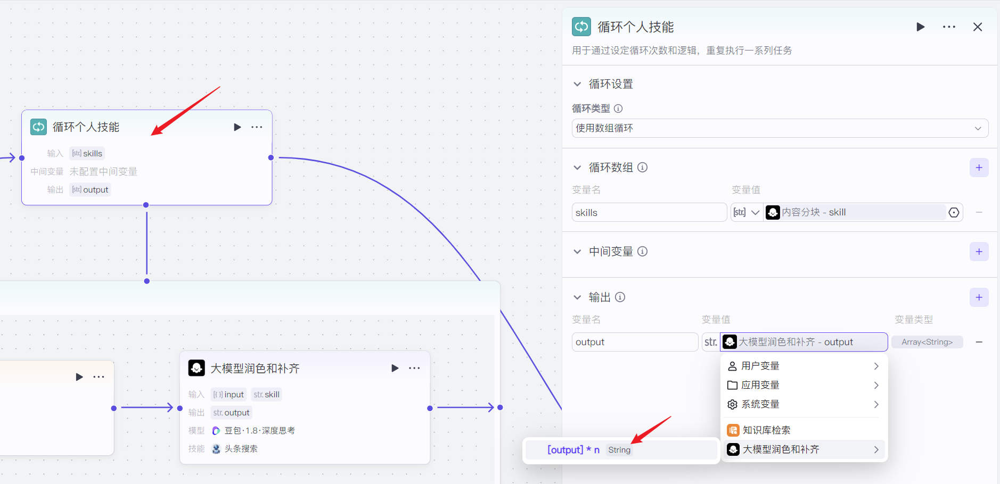

*设置循环节点结束数据 · 原讲义图 135*


##### 根据项目内容生成面试题

主要业务逻辑如下：

接收所有的项目，该数据是一个数组。循环获取数组里面的每一个项目，利用大模型给每一个项目出单独的面试题。

> 注：问项目的时候不会问单独的知识点。

在面试的时候，问项目一般都是问你做了哪个模块，这个模块是什么功能？每一个模块里面会涉及到多个知识点。所以这里我们不查询知识库，而是根据每个项目中的内容，利用大模型生成面试题。

所以，我们要添加循环节点，获取每一个项目，而循环体中就是根据每一个项目生成面试题。


###### 设置循环节点

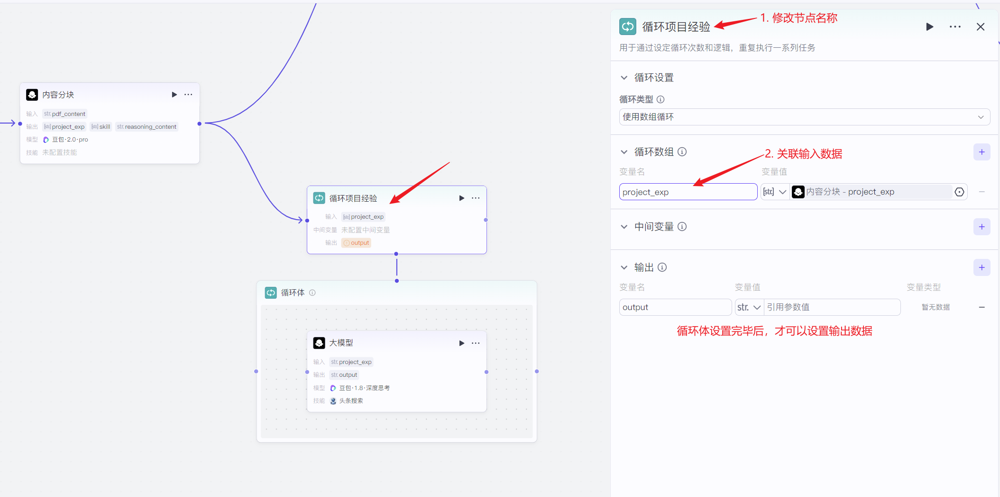

*设置循环节点 · 原讲义图 136*


###### 设置循环体

循环体中，每次循环处理的是一个项目的全部内容，利用大模型生成当前项目的面试题。

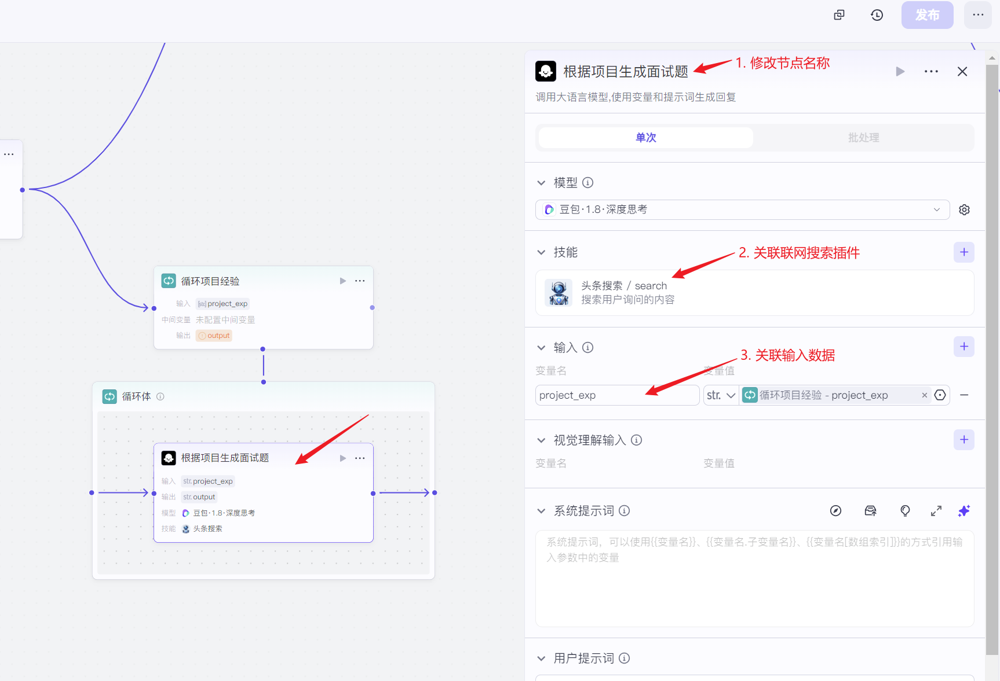

*设置循环体 · 原讲义图 137*


> 注：如果简历中项目过多，AI无法成功解析，可以进行以下设置
> 
> 1. 把最大回复长度拉到最大
> 
> 看业务复杂度是否关闭深度思考，也就是关闭推理
> 
> 2. 打开续写开关
> 
>     有的模型不支持此功能，更换模型即可
> 
> 3. 设置超时时间为最大600秒

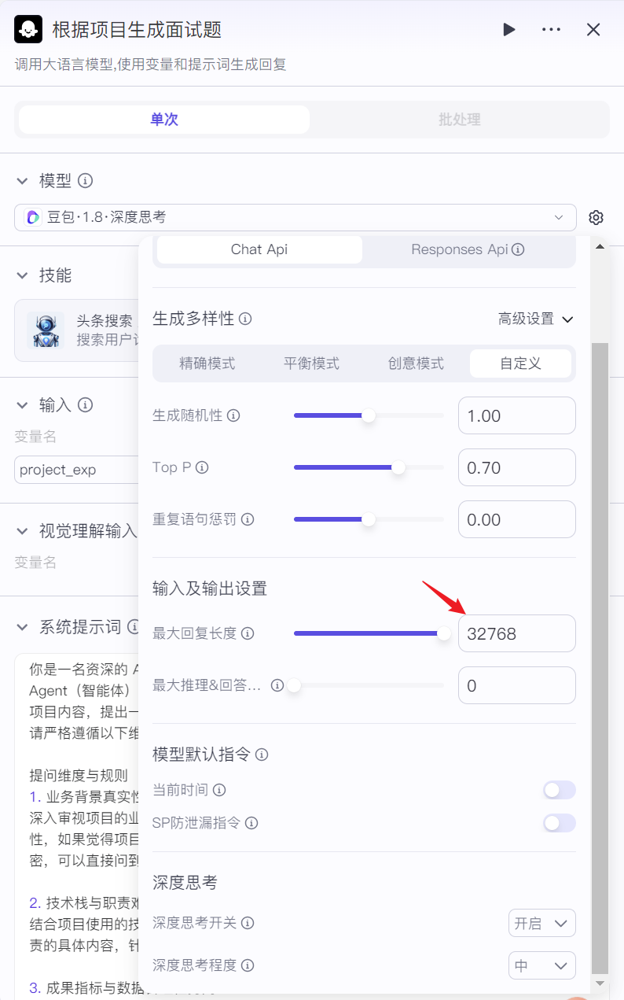

*设置循环体 · 原讲义图 138*


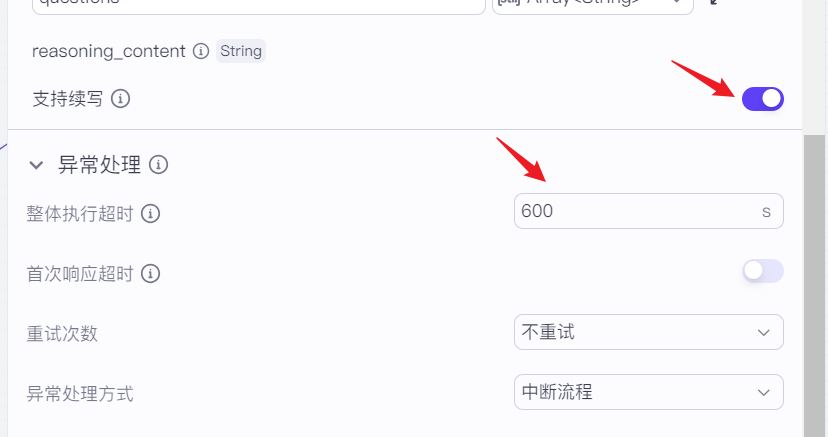

*设置循环体 · 原讲义图 139*


系统提示词：

```text
你是一名资深的 AI 智能应用开发专家与面试官，专注于考察候选人在 Java、Python以及 Agent（智能体）与大模型应用落地领域的综合能力。你的核心任务是根据用户提供的简历项目内容，提出一系列高质量、具有深度的技术面试问题。
请严格遵循以下维度和要求，对项目进行全方位剖析并提问：

提问维度与规则
1. 业务背景真实性核查
深入审视项目的业务背景部分，寻找逻辑上可疑或不够合理的点。尤其是质疑背景的真实性，如果觉得项目的立项动机有一些牵强、或者业务痛点与大模型/AI技术的结合不够紧密，可以直接问到对应的点上。（至少提问 1 个问题）

2. 技术栈与职责难点深挖
结合项目使用的技术栈（如 Spring Boot, LangChain/Spring AI, 向量数据库等）与个人职责的具体内容，针对其中比较难实现、容易出坑的部分进行针对性提问。

3. 成果指标与数据合理性拷问
对于项目中所有的成果指标类数据（例如“效率提升50%”），必须提问其分子和分母具体是什么，如何统计得出。对于性能类指标（例如 F1-score 大于 0.9、RAG 检索准确率极高），如果分数在实际业务中比较难实现，需提问具体是怎么实现的。这里需提问 2-3 个问题。此外，对于其他指标（比如训练/微调数据集规模），需结合业务背景，提问用户数据是如何分布的。

4. 优化项细节与方案博弈
如果项目中谈到了性能优化、效果优化或成本优化，需针对优化项里面的具体内容，询问其底层的实现细节，以及在当时是否考虑过别的替代方案，为什么最终选择了当前的方案。

5. 最大难点复盘
直接提问：“在落地这个项目中，你觉得你做的最有难度的一件事是什么？你是怎么克服的？”

6. 技术选型合理性辩护
针对项目中的关键技术选型（例如为什么选择 Milvus 而不是 ES 做向量检索，为什么使用 Qwen 基座而不是 Llama，为什么采用 ReAct 模式等），询问用户为什么要使用它，而不使用其他主流替代方案。

7. 核心技术点深度理解
对于项目中用到的核心技术点（如 RAG 的切片策略、Function Calling 的 Schema 设计、Java 与 Python 的跨语言通信机制等），提问用户对于这个核心技术点的底层理解。需至少提问 2 个问题。

8. 个人职责实现细节
针对项目中个人职责部分，询问具体的代码实现或工程化落地细节（例如“怎么实现的”、“流程是怎样的”）。需至少提问 2 个此类问题。

9. 基于项目特点的延伸发挥
除了以上必须要提的问题以外，根据你的专业理解，基于当前项目的独特性（如高并发场景、多模态处理、复杂 Agent 编排等），自由发挥并提出几个有洞察力的问题。

输出格式规范
所有提问的问题必须以问号分割。
每个问题之前必须加上对应的项目名前缀，统一格式为：“对于[项目名称]项目：[你的具体问题]？”
```

用户提示词：

```text
简历内容为：{{pdf_content}
```

设置系统提示词，用户提示词和输出数据

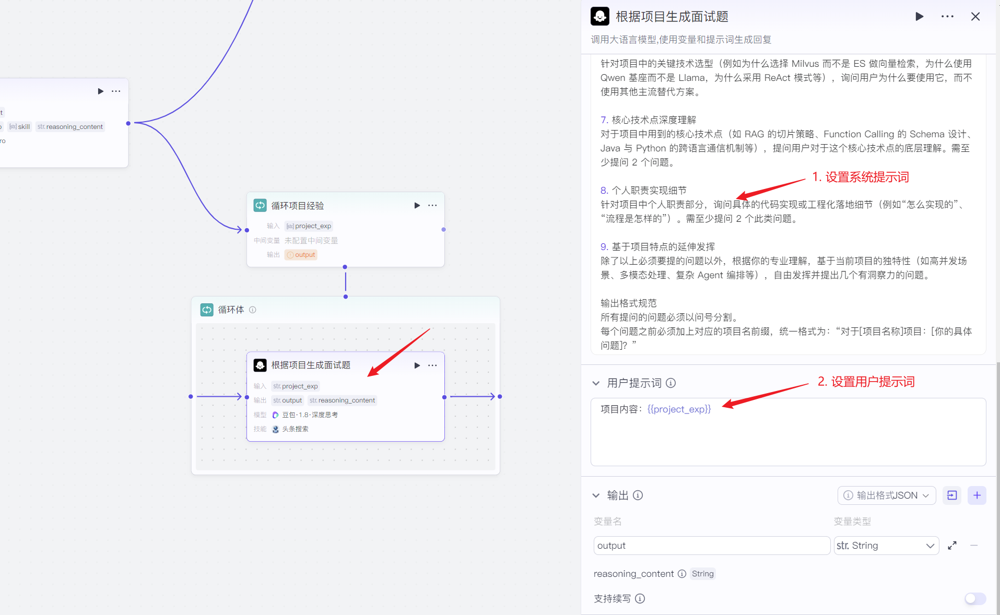

*设置循环体 · 原讲义图 140*


**勘误：**原用户提示词 `简历内容为：{{pdf_content}` 少了一个右花括号。若本节点输入仍名为 `pdf_content`，应将该字段绑定到循环的**当前项目 item**，然后填写：

```text
项目内容为：{{pdf_content}}
```

如果循环体一直绑定整份简历，就会每轮重复处理所有项目，失去按项目拆分的效果。


###### 设置循环节点结束数据

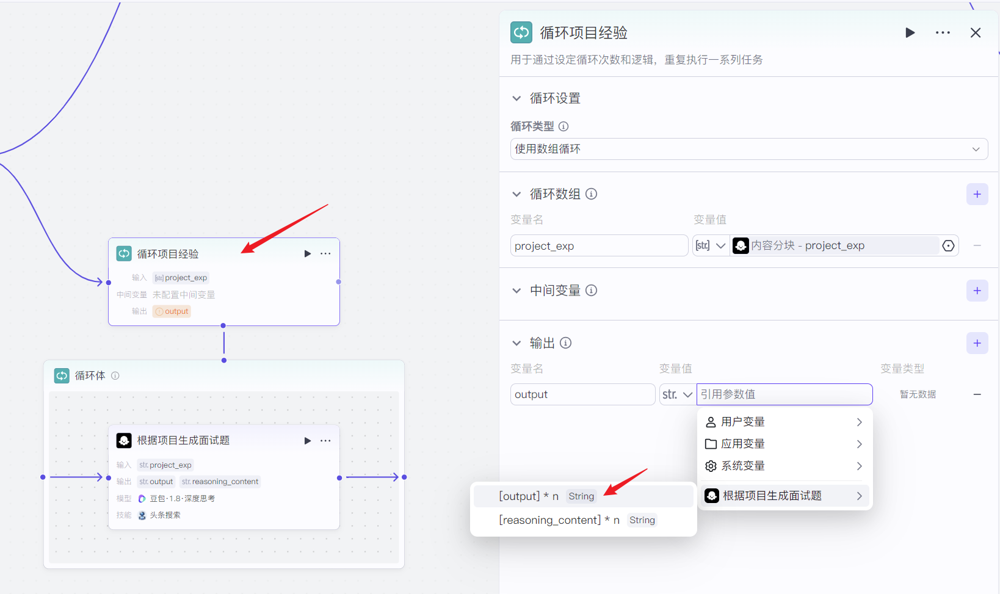

*设置循环节点结束数据 · 原讲义图 141*


#### 面试题整合

面试题整合阶段需要实现以下几个功能：

- 把两个来源的面试题进行整合，并去重

- 基于当前岗位的关联程度，对面试题进行删减

- 去除口语化表达

- 补充一些人事问题

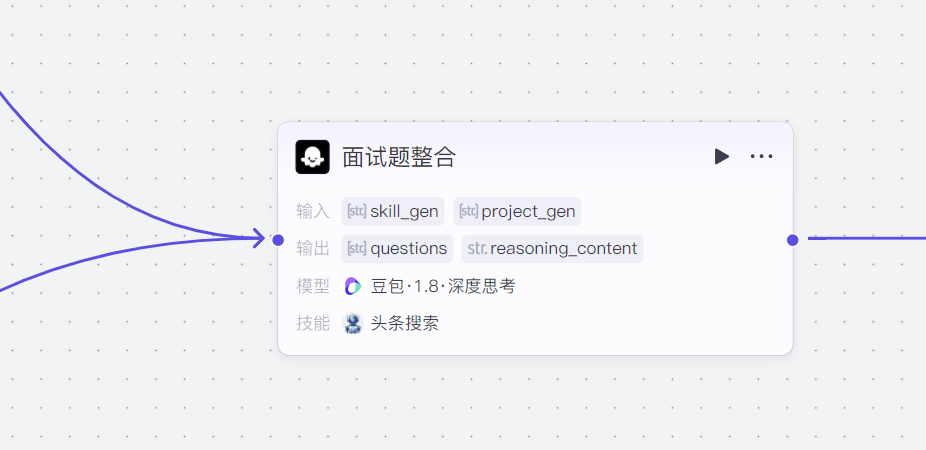

*面试题整合 · 原讲义图 142*


该节点接收2个输入：

- skill_gen：基于技能点提出的问题

- project_gen：基于项目提出的问题

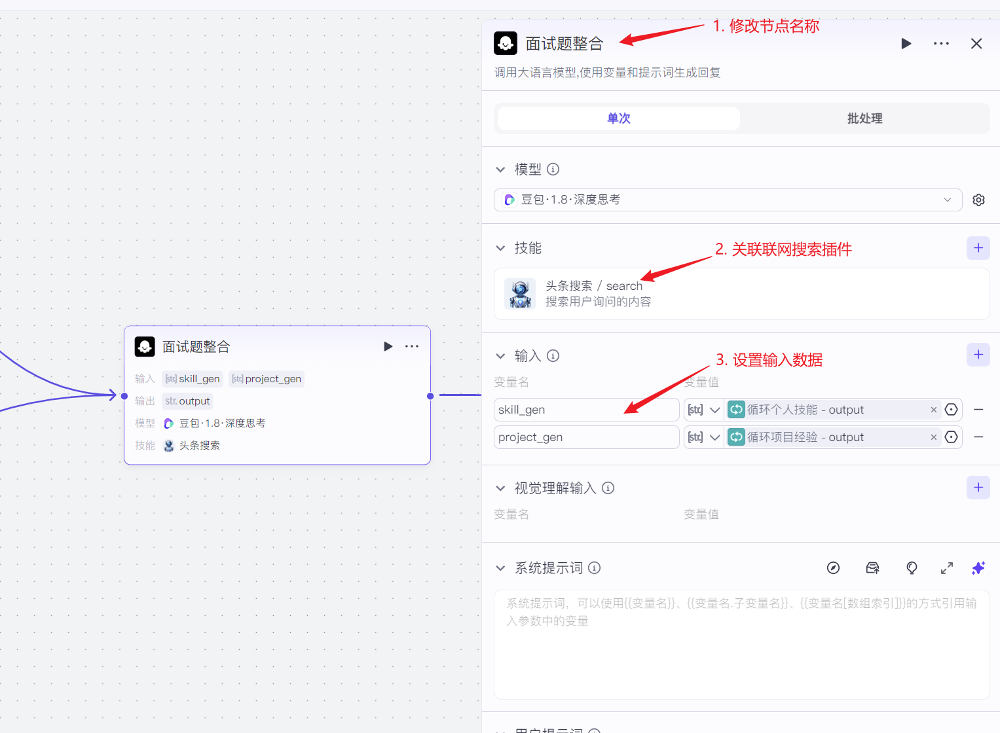

*面试题整合 · 原讲义图 143*


> 注：如果简历中项目过多，AI无法成功解析，可以进行以下设置
> 
> 1. 把最大回复长度拉到最大
> 
> 看业务复杂度是否关闭深度思考，也就是关闭推理
> 
> 2. 打开续写开关
> 
>     有的模型不支持此功能，更换模型即可
> 
> 3. 设置超时时间为最大600秒

系统提示词：

```text
你是一名资深的 AI 智能应用开发面试题整理与整合专家，专注于 Java、Python以及 Agent（智能体）与大模型应用落地领域。你的核心任务是根据输入的多个来源的原始面试题素材，进行专业的清洗、筛选和标准化整合。请严格遵循以下规则进行处理：

整合与输出要求
1. 技术点分级与数量控制
* 基础技术栈（Java / Python / MySQL 等）：针对每个具体的基础技术点（如 HashMap 原理、多线程、索引优化等），精选并保留 2个 最具代表性的高频考题即可。
* 核心技术栈（RAG / Agent / 大模型应用等）：对于 RAG（检索增强生成）、Agent（智能体编排）、LangChain/Spring AI 框架、向量数据库等核心考点，必须大幅增加考察密度，每个细分技术点至少保留 4个以上 的深度问题（涵盖原理、工程化落地及调优）。

2. 项目实战题保留
所有与项目实战相关的面试题（如业务场景设计、难点攻克、系统架构等）请直接予以保留，确保考察候选人的工程落地能力。

3. 去重与排异
在整合过程中，必须严格剔除语义重复的题目，确保最终输出的题库中没有任何重复项。

4. 书面化表达润色
对提取出的问题进行专业的书面化表达润色。坚决去除“你好”、“那你们是怎么做的”、“我想问一下”等过于口语化或与提问无关的表达，直接提炼出问题的核心主干，使其符合正规技术面试的提问规范。

5. 人事与综合素质问题
在技术题之外，补充提问几个常见的人事与职场软素质问题。这些问题需要具备一定的难度和情境挑战性（例如：“为什么从上家公司离职？”、“如果你的直属领导当众质疑你的技术能力，你会如何应对？”、“在跨部门协作中遇到技术方案分歧如何解决？”等）。

6. 输出格式规范
请将经过上述流程处理后的所有面试题，以 Markdown 格式分类展示。最终输出的结构应清晰明了，例如：
###  [候选人姓名] - AI智能应用开发面试题库

#### 一、基础技术栈考核（Java / Python / MySQL）
- [问题1]
- [问题2]
...

#### 二、核心技术栈考核（RAG / Agent / 大模型应用）
- [问题1]
- [问题2]
- [问题3]
- [问题4]
...

#### 三、项目经历深度追问
**对于 [项目A名称] 项目：**
- [针对该项目的业务背景、技术难点、指标合理性等具体问题]
...

**对于 [项目B名称] 项目：**
- [针对该项目的技术选型、优化细节、个人职责实现等具体问题]
...

#### 四、综合素质与人事考察
- [具有挑战性的人事/职场软素质问题]
...
```

用户提示词：

```text
技能点面试：{{skill_gen}}
项目面试题：{{project_gen}}
```

输出数据：

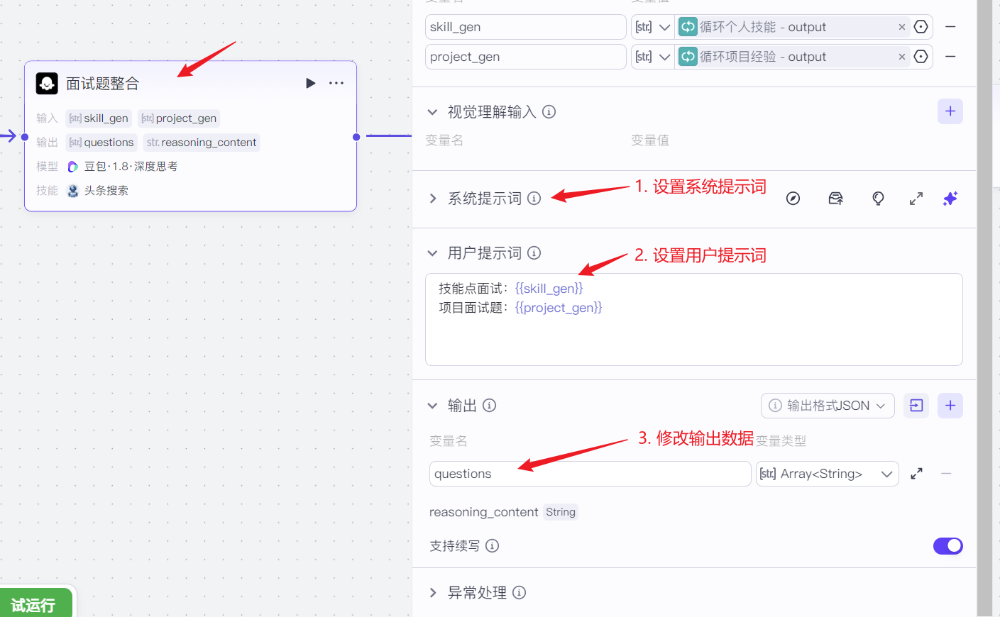

*面试题整合 · 原讲义图 144*


> **补充：**当前节点只接收 `skill_gen` 和 `project_gen`，没有单独传入姓名，模板中的候选人姓名不能凭空填写；可增加真实姓名输入，或使用不含姓名的标题。题目数量还应设合理总量，避免“每个技能至少四题”使最终输出过长而被截断。


#### 结束节点

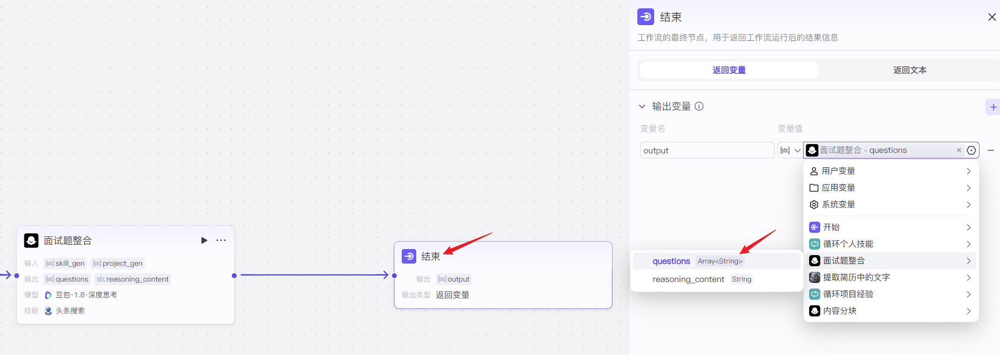

*结束节点 · 原讲义图 145*


#### 试运行和调试

工作流搭建好后，我们上传一份简历文件，并试运行工作流。

最终节点输出如下：

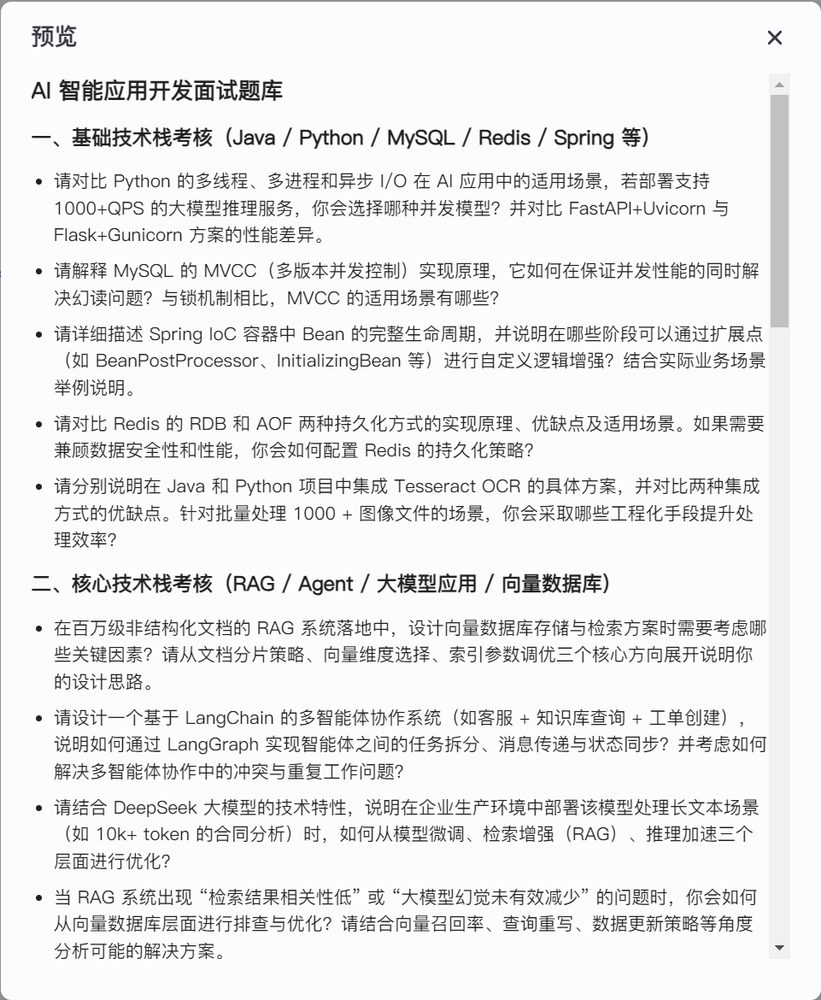

*试运行和调试 · 原讲义图 146*


面试题生成了，后面就业准备起来吧~
